# Ir Além — Transfer Learning, Fine Tuning e Segmentação Automática

**FIAP — Fase 6 · Opção 2 do "Ir Além"**

Problema: classificar imagens em **vaca** ou **trator** com um dataset pequeno (80 imagens: 32/4/4 por classe em treino/validação/teste).

Este notebook é autossuficiente e está organizado em quatro partes:

1. **Parte A — Transfer Learning + Fine Tuning (hipótese A):** uma rede grande pré-treinada na ImageNet (MobileNetV2) supera uma CNN treinada do zero com os mesmos dados, sementes e divisão?
2. **Parte B — Segmentação automática (hipótese B):** recortar o objeto principal (fundo preto) antes de classificar melhora a acurácia? Inclui métricas de qualidade das máscaras, tempo por etapa e os casos difíceis.
3. **Parte C — Comparação final** das 4 combinações (do zero / transfer × original / segmentada): 3 sementes, validação cruzada 5-fold, teste pareado de McNemar, efeito do fine tuning e análise dos erros.
4. **Parte D — Além do teto:** a MobileNetV2 acerta 100% em tudo, o que impede medir a hipótese B para ela. Uma sondagem linear com **poucas imagens por classe** (1 a 32), comparando pesos ImageNet com pesos aleatórios e imagens originais, segmentadas e **só com o fundo**, torna as duas hipóteses mensuráveis a custo de segundos.

![Pipeline](https://raw.githubusercontent.com/leticiael/leticiaeltermann-fiap-fase6-visao-computacional/main/ir_alem/figuras/pipeline.png)

## 0. Configuração do ambiente

Detecta se está no Google Colab. No Colab, monta o Google Drive, aponta para `/content/drive/MyDrive/fiap_fase6` e instala o `ultralytics` **na versão testada (8.4.175)**, se a versão instalada for outra. Localmente, usa a pasta do projeto (o pai de `ir_alem/`). Também define as pastas de saída: figuras, dataset segmentado e cache de pesos.

No Colab o dataset segmentado vai para `/content/dataset_segmentado` (disco local da VM), e não para o Drive. São 160 arquivos pequenos (imagens + máscaras): gravar no Drive montado é lento e ele não precisa persistir, porque é regenerado de forma determinística em menos de 1 minuto na GPU. As figuras e CSVs, que são entregáveis, continuam no Drive. Os pesos dos modelos (YOLO-World, SAM 2 e CLIP, ~650 MB) ficam em `~/.cache`, fora do projeto.

In [1]:
import importlib
import importlib.metadata
import importlib.util
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
ULTRALYTICS_VERSION = "8.4.175"


def mount_drive() -> None:
    from google.colab import drive
    drive.mount("/content/drive")


def installed_version(name: str) -> str | None:
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def ensure_package(name: str, version: str) -> None:
    if installed_version(name) != version:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"{name}=={version}"], check=True)


def find_project_dir() -> Path:
    if IN_COLAB:
        return Path("/content/drive/MyDrive/fiap_fase6")
    here = Path.cwd().resolve()
    return here.parent if here.name == "ir_alem" else here


if IN_COLAB:
    mount_drive()
    ensure_package("ultralytics", ULTRALYTICS_VERSION)

PROJECT_DIR = find_project_dir()
DATASET_DIR = PROJECT_DIR / "dataset" / "images"
IR_ALEM_DIR = PROJECT_DIR / "ir_alem"
FIGURES_DIR = IR_ALEM_DIR / "figuras"
SEGMENTED_DIR = Path("/content/dataset_segmentado") if IN_COLAB else IR_ALEM_DIR / "dataset_segmentado"
WEIGHTS_DIR = Path.home() / ".cache" / "fiap_ir_alem_pesos"

for folder in (FIGURES_DIR, SEGMENTED_DIR, WEIGHTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print(f"Colab: {IN_COLAB}")
print(f"Dataset: {DATASET_DIR}")
print(f"Saídas: {IR_ALEM_DIR}")
print(f"ultralytics: {installed_version('ultralytics')}")

Colab: False
Dataset: C:\Users\leelt\fiap-fase6\dataset\images
Saídas: C:\Users\leelt\fiap-fase6\ir_alem
ultralytics: 8.4.175


### Bibliotecas, dispositivos e constantes globais

Concentra todas as importações e as constantes do experimento: classes (deduzidas do prefixo do nome do arquivo), resolução 224×224, sementes repetidas, hiperparâmetros de treino, aumento de dados e figuras. Todas as combinações usam **exatamente** as mesmas sementes e a mesma divisão treino/validação/teste.

Logo após importar o TensorFlow, e **antes** do PyTorch, ativa o *memory growth* em cada GPU. Sem isso, no Colab o TensorFlow reserva quase toda a VRAM e o PyTorch (YOLO-World, CLIP e SAM 2, na Parte B) falha por falta de memória. A célula imprime o dispositivo usado pelo TensorFlow (`TF_DEVICE`) e pelo PyTorch (`TORCH_DEVICE`); os tempos se referem a esses dispositivos.

Também define formatadores com vírgula decimal para os textos gerados em português e duas funções de saída de figuras: gráficos são exibidos em PNG; grades de fotos são salvas em PNG na pasta `figuras/`, mas exibidas no notebook em JPEG, o que mantém o `.ipynb` leve.

In [2]:
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import io
import time
import warnings
from typing import Any, Callable

import tensorflow as tf


def enable_gpu_memory_growth() -> None:
    for gpu in tf.config.list_physical_devices("GPU"):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as error:
            print(f"Memory growth não ativado em {gpu.name} (GPU já inicializada): {error}")


enable_gpu_memory_growth()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image as IPythonImage
from IPython.display import Markdown, display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from PIL import Image
from scipy.stats import beta, binomtest
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import mobilenet_v2
from ultralytics import SAM, YOLOWorld

warnings.filterwarnings("ignore", category=FutureWarning, module="torch")
tf.get_logger().setLevel("ERROR")

CLASSES = ("vaca", "trator")
SPLITS = ("train", "val", "test")
IMG_SIZE = 224
BATCH_SIZE = 16
SEEDS = (42, 7, 2024)
DECISION_THRESHOLD = 0.5
LOG_LOSS_EPSILON = 1e-7
INFERENCE_REPEATS = 5
CONFIDENCE_LEVEL = 0.95

AUGMENT_ROTATION = 0.08
AUGMENT_ZOOM = 0.15
AUGMENT_CONTRAST = 0.15

SCRATCH_EPOCHS = 40
SCRATCH_LR = 1e-3
SCRATCH_BN_MOMENTUM = 0.9
SCRATCH_FILTERS = (32, 64, 128, 256)
SCRATCH_DROPOUT = 0.4
TRANSFER_DROPOUT = 0.3
HEAD_EPOCHS = 15
HEAD_LR = 1e-3
FINE_TUNE_EPOCHS = 10
FINE_TUNE_LR = 1e-5
FINE_TUNE_FROM_LAYER = "block_15_expand"

FIGURE_DPI = 130
PHOTO_GRID_DPI = 90
JPEG_QUALITY = 85

MODEL_SCRATCH = "CNN do zero"
MODEL_TRANSFER = "MobileNetV2 (transfer + fine tuning)"
VARIANT_ORIGINAL = "Original"
VARIANT_SEGMENTED = "Segmentada"
VARIANT_BACKGROUND = "Só fundo"
VARIANT_COLORS = {VARIANT_ORIGINAL: "#2a78d6", VARIANT_SEGMENTED: "#eb6834", VARIANT_BACKGROUND: "#8e5bc8"}
CLASS_COLORS = {"vaca": "#2f9e6b", "trator": "#8e5bc8"}

TF_DEVICE = "GPU" if tf.config.list_physical_devices("GPU") else "CPU"
TORCH_DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"


def decimal(value: float, digits: int = 1) -> str:
    return f"{value:.{digits}f}".replace(".", ",")


def percent(value: float, digits: int = 1) -> str:
    return f"{decimal(100 * value, digits)}%"


def thousands(value: int) -> str:
    return f"{value:,}".replace(",", ".")


def p_value(value: float) -> str:
    return "< 0,001" if value < 0.001 else decimal(value, 3)


def save_chart(fig: plt.Figure, path: Path) -> None:
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    plt.show()


def save_photo_grid(fig: plt.Figure, path: Path) -> None:
    fig.savefig(path, dpi=PHOTO_GRID_DPI, bbox_inches="tight")
    buffer = io.BytesIO()
    fig.savefig(buffer, format="jpeg", dpi=PHOTO_GRID_DPI, bbox_inches="tight", pil_kwargs={"quality": JPEG_QUALITY})
    plt.close(fig)
    display(IPythonImage(data=buffer.getvalue(), format="jpeg"))


print(f"TensorFlow {tf.__version__} · dispositivo de treino (TF_DEVICE): {TF_DEVICE}")
print(f"PyTorch {torch.__version__} · dispositivo da segmentação (TORCH_DEVICE): {TORCH_DEVICE}")

TensorFlow 2.19.0 · dispositivo de treino (TF_DEVICE): CPU
PyTorch 2.14.1+cu126 · dispositivo da segmentação (TORCH_DEVICE): cuda:0


### Figura autoral do pipeline

Desenha com `matplotlib` (caixas e setas) o fluxo completo do experimento, salva em `figuras/pipeline.png` e exibe a figura.

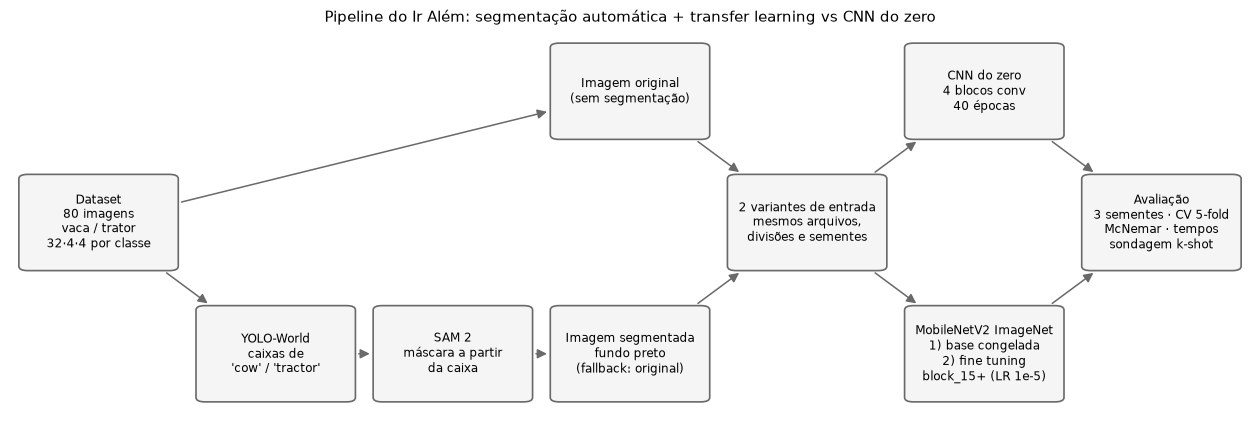

In [3]:
PIPELINE_BOXES = {
    "dados": (0.00, 0.42, "Dataset\n80 imagens\nvaca / trator\n32·4·4 por classe"),
    "detector": (0.20, 0.12, "YOLO-World\ncaixas de\n'cow' / 'tractor'"),
    "sam": (0.40, 0.12, "SAM 2\nmáscara a partir\nda caixa"),
    "segmentada": (0.60, 0.12, "Imagem segmentada\nfundo preto\n(fallback: original)"),
    "original": (0.60, 0.72, "Imagem original\n(sem segmentação)"),
    "variantes": (0.80, 0.42, "2 variantes de entrada\nmesmos arquivos,\ndivisões e sementes"),
    "zero": (1.00, 0.72, "CNN do zero\n4 blocos conv\n40 épocas"),
    "transfer": (1.00, 0.12, "MobileNetV2 ImageNet\n1) base congelada\n2) fine tuning\nblock_15+ (LR 1e-5)"),
    "avaliacao": (1.20, 0.42, "Avaliação\n3 sementes · CV 5-fold\nMcNemar · tempos\nsondagem k-shot"),
}
PIPELINE_ARROWS = (
    ("dados", "original"), ("dados", "detector"), ("detector", "sam"), ("sam", "segmentada"),
    ("original", "variantes"), ("segmentada", "variantes"),
    ("variantes", "zero"), ("variantes", "transfer"), ("zero", "avaliacao"), ("transfer", "avaliacao"),
)
BOX_WIDTH, BOX_HEIGHT = 0.16, 0.2


def box_center(key: str) -> tuple[float, float]:
    x, y, _ = PIPELINE_BOXES[key]
    return x + BOX_WIDTH / 2, y + BOX_HEIGHT / 2


def draw_box(ax: plt.Axes, key: str) -> FancyBboxPatch:
    x, y, text = PIPELINE_BOXES[key]
    patch = FancyBboxPatch((x, y), BOX_WIDTH, BOX_HEIGHT, boxstyle="round,pad=0.01",
                           facecolor="whitesmoke", edgecolor="dimgray", linewidth=1.2)
    ax.add_patch(patch)
    ax.text(x + BOX_WIDTH / 2, y + BOX_HEIGHT / 2, text, ha="center", va="center", fontsize=8.5)
    return patch


def draw_arrow(ax: plt.Axes, patches: dict[str, FancyBboxPatch], start: str, end: str) -> None:
    ax.add_patch(FancyArrowPatch(box_center(start), box_center(end), patchA=patches[start], patchB=patches[end],
                                 arrowstyle="-|>", mutation_scale=14, color="dimgray", shrinkA=2, shrinkB=2,
                                 linewidth=1.1))


def draw_pipeline(path: Path) -> None:
    fig, ax = plt.subplots(figsize=(16, 5))
    patches = {key: draw_box(ax, key) for key in PIPELINE_BOXES}
    for start, end in PIPELINE_ARROWS:
        draw_arrow(ax, patches, start, end)
    ax.set_xlim(-0.02, 1.38)
    ax.set_ylim(0.08, 0.96)
    ax.axis("off")
    ax.set_title("Pipeline do Ir Além: segmentação automática + transfer learning vs CNN do zero", fontsize=11)
    save_chart(fig, path)


draw_pipeline(FIGURES_DIR / "pipeline.png")

### Carregamento dos dados

Lê as imagens de cada split, redimensiona para 224×224 (tamanho nativo da MobileNetV2 na ImageNet) e extrai o rótulo do prefixo do nome (`vaca_NNN.jpg` → 0, `trator_NNN.jpg` → 1). O redimensionamento é direto (sem recorte central) para não cortar o objeto, que costuma ocupar boa parte do quadro. Os pixels ficam em `[0, 255]`; cada modelo aplica o próprio pré-processamento dentro do grafo.

In [4]:
Split = dict[str, Any]
Dataset = dict[str, Split]


def label_from_path(path: Path) -> int:
    return CLASSES.index(path.stem.split("_")[0])


def load_image(path: Path) -> np.ndarray:
    image = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(image, dtype=np.float32)


def list_images(root: Path, split: str) -> list[Path]:
    return sorted(path for path in (root / split).iterdir() if path.suffix.lower() in {".jpg", ".jpeg", ".png"})


def load_split(root: Path, split: str) -> Split:
    paths = list_images(root, split)
    images = np.stack([load_image(path) for path in paths])
    labels = np.array([label_from_path(path) for path in paths], dtype=np.float32)
    return {"paths": paths, "x": images, "y": labels}


def load_dataset(root: Path) -> Dataset:
    return {split: load_split(root, split) for split in SPLITS}


original_data = load_dataset(DATASET_DIR)
for split, part in original_data.items():
    counts = {name: int((part["y"] == index).sum()) for index, name in enumerate(CLASSES)}
    print(f"{split:5s}: {len(part['y'])} imagens {counts}")

train: 64 imagens {'vaca': 32, 'trator': 32}
val  : 8 imagens {'vaca': 4, 'trator': 4}
test : 8 imagens {'vaca': 4, 'trator': 4}


---
## Parte A — Transfer Learning + Fine Tuning (TensorFlow/Keras)

### Por que MobileNetV2?

* **Dataset minúsculo (64 imagens de treino):** treinar milhões de pesos do zero leva a overfitting; reaproveitar filtros aprendidos em 1,28 milhão de imagens da ImageNet (que **contém** classes de bovinos e de veículos agrícolas/tratores) dá representações prontas.
* **Leve e rápida:** ~2,3 M parâmetros na base convolucional (~14 MB). Treina em poucos minutos mesmo sem GPU, então o notebook roda em qualquer máquina; o dispositivo efetivamente usado é o `TF_DEVICE` impresso na célula de bibliotecas.
* **Boa acurácia na ImageNet** (~71,3% top-1) para o custo, com convoluções separáveis em profundidade e blocos *inverted residual*.
* Alternativas maiores (ResNet50, EfficientNetB3) teriam mais capacidade do que 64 imagens conseguem ajustar e custariam muito mais tempo. Como a MobileNetV2 já atinge o teto de 100% (Parte C), uma rede maior não teria como mostrar ganho de acurácia neste dataset.

### Pré-processamento

* **224×224:** resolução em que os pesos ImageNet foram treinados; mantém a escala dos filtros.
* **`mobilenet_v2.preprocess_input`:** a MobileNetV2 foi treinada com pixels em `[-1, 1]` (`x/127.5 − 1`). Usar outra escala deslocaria as ativações dos BatchNorms congelados. O passo está **dentro** do modelo (após o aumento), então o modelo recebe pixels crus.
* **Aumento de dados** (só no treino): flip horizontal, rotação de ±8% de volta (≈ ±29°), zoom ±15% e contraste ±15%. São transformações plausíveis para fotos de campo (uma vaca espelhada continua sendo vaca) e combatem a memorização das 64 imagens. Sem flip vertical: vacas e tratores de cabeça para baixo não existem no problema.

### Blocos de construção dos modelos

Define o aumento de dados compartilhado, a **CNN do zero** (baseline compacto: 4 blocos Conv-BN-ReLU-MaxPool com 32→256 filtros, *global average pooling*, dropout 0,4 e saída sigmoide; pixels escalados para `[0, 1]`; BatchNorm com `momentum=0.9`) e a **MobileNetV2** com cabeça nova (GAP → Dropout 0,3 → Dense sigmoide). A base é chamada com `training=False` e, no fine tuning, as camadas BatchNorm continuam **congeladas** (ver abaixo) — com lotes de 16 imagens, atualizar suas médias destruiria as estatísticas da ImageNet.

In [5]:
def build_augmentation() -> keras.Sequential:
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(AUGMENT_ROTATION),
        layers.RandomZoom(AUGMENT_ZOOM),
        layers.RandomContrast(AUGMENT_CONTRAST),
    ], name="aumento_de_dados")


def conv_block(x: keras.KerasTensor, filters: int) -> keras.KerasTensor:
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization(momentum=SCRATCH_BN_MOMENTUM)(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)


def classification_head(x: keras.KerasTensor, dropout: float) -> keras.KerasTensor:
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    return layers.Dense(1, activation="sigmoid")(x)


def build_scratch_model() -> keras.Model:
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1 / 255)(x)
    for filters in SCRATCH_FILTERS:
        x = conv_block(x, filters)
    return keras.Model(inputs, classification_head(x, SCRATCH_DROPOUT), name="cnn_do_zero")


def build_mobilenet_base(weights: str | None = "imagenet") -> keras.Model:
    return keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights=weights)


def build_transfer_model() -> tuple[keras.Model, keras.Model]:
    base = build_mobilenet_base()
    base.trainable = False
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = build_augmentation()(inputs)
    x = layers.Lambda(mobilenet_v2.preprocess_input, name="preprocess_mobilenet_v2")(x)
    x = base(x, training=False)
    return keras.Model(inputs, classification_head(x, TRANSFER_DROPOUT), name="mobilenetv2_transfer"), base


def compile_model(model: keras.Model, learning_rate: float) -> None:
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="binary_crossentropy", metrics=["accuracy"])

> **Armadilha encontrada durante o desenvolvimento:** com o `momentum=0.99` padrão do Keras, as médias móveis do BatchNorm da CNN do zero recebem só 4 lotes por época (160 atualizações em 40 épocas, `0,99^160 ≈ 20%` ainda do valor inicial). No modo de inferência o modelo usava estatísticas erradas e previa uma única classe para tudo (acurácia de 50%, o acaso, até nas próprias imagens de **treino**, embora a acurácia exibida durante o `fit` fosse alta). Com `momentum=0.9` as médias convergem e o baseline fica justo.

### Qual camada descongelar no fine tuning?

Lista o fim da MobileNetV2 para localizar o ponto de corte. A base tem 17 blocos *inverted residual*. Descongelamos a partir de **`block_15_expand`**, ou seja, os **dois últimos blocos (15 e 16) + `Conv_1`**:

* As camadas iniciais aprendem bordas, cores e texturas genéricas — úteis para qualquer foto e caras de reajustar com 64 imagens.
* Os blocos 15–16 (7×7, 160→320 canais) e a `Conv_1` (1280 canais) codificam partes de objetos específicas das classes ImageNet; são eles que precisam ser adaptados para "vaca vs trator".
* Descongelar mais (ex.: a partir do bloco 13) aumentaria os pesos treináveis com o mesmo punhado de exemplos → overfitting e esquecimento catastrófico. Com LR baixo (1e-5, 100× menor que o da cabeça) os pesos pré-treinados só são ajustados finamente.
* **BatchNorm fica congelado mesmo dentro dos blocos descongelados.** Testamos: no Keras 3, um BN com `trainable=True` volta a usar as estatísticas do lote mesmo com `training=False` na chamada da base. Num teste preliminar com lotes de 16 imagens, isso derrubou a acurácia de treino logo na primeira época de fine tuning e multiplicou a perda. Com os BNs congelados, o fine tuning continua de onde o estágio 1 parou e a perda segue caindo (ver as curvas abaixo).

In [6]:
def layer_index(model: keras.Model, name: str) -> int:
    return next(index for index, layer in enumerate(model.layers) if layer.name == name)


def count_parameters(weights: list[Any]) -> int:
    return int(sum(np.prod(weight.shape) for weight in weights))


def fine_tunable_layers(base: keras.Model, start_index: int) -> list[layers.Layer]:
    return [layer for index, layer in enumerate(base.layers)
            if index >= start_index and layer.weights and not isinstance(layer, layers.BatchNormalization)]


def layers_parameters(chosen: list[layers.Layer]) -> int:
    return count_parameters([weight for layer in chosen for weight in layer.trainable_weights])


inspection_base = build_mobilenet_base()
FINE_TUNE_FROM_INDEX = layer_index(inspection_base, FINE_TUNE_FROM_LAYER)
unfrozen_layers = fine_tunable_layers(inspection_base, FINE_TUNE_FROM_INDEX)
unfrozen_parameters = layers_parameters(unfrozen_layers)

print(f"Camadas na base: {len(inspection_base.layers)}")
print(f"Descongelar a partir do índice {FINE_TUNE_FROM_INDEX} ({FINE_TUNE_FROM_LAYER}): "
      f"{len(unfrozen_layers)} camadas com pesos treináveis (BatchNorm excluído)")
print(f"Parâmetros treináveis no fine tuning: {thousands(unfrozen_parameters)} de {thousands(inspection_base.count_params())}")
print([layer.name for layer in unfrozen_layers])

Camadas na base: 154
Descongelar a partir do índice 134 (block_15_expand): 7 camadas com pesos treináveis (BatchNorm excluído)
Parâmetros treináveis no fine tuning: 1.194.880 de 2.257.984
['block_15_expand', 'block_15_depthwise', 'block_15_project', 'block_16_expand', 'block_16_depthwise', 'block_16_project', 'Conv_1']


### Custo de cada ponto de corte possível

Compara, para os cortes candidatos, quantas camadas e quantos parâmetros passariam a ser treinados (BatchNorm sempre congelado). É a evidência quantitativa por trás da escolha: os últimos blocos concentram boa parte dos pesos da rede, então cada bloco a mais descongelado aumenta bastante o número de pesos ajustados com as mesmas 64 imagens. Não comparamos os cortes por acurácia porque o estágio 1 (base toda congelada) já chega a 100% (ver a tabela do efeito do fine tuning, na Parte C): nesse regime, acurácia não discrimina cortes. O corte escolhido é o menor que ainda inclui um bloco inteiro de 160 canais e a `Conv_1`.

In [7]:
FINE_TUNE_CANDIDATES = ("block_13_expand", "block_14_expand", "block_15_expand", "block_16_expand", "Conv_1")


def cut_point_row(base: keras.Model, name: str) -> dict[str, Any]:
    chosen = fine_tunable_layers(base, layer_index(base, name))
    parameters = layers_parameters(chosen)
    return {"descongelar a partir de": name, "camadas com pesos": len(chosen), "parâmetros treináveis": thousands(parameters),
            "% da base": percent(parameters / base.count_params()), "escolhido": "sim" if name == FINE_TUNE_FROM_LAYER else ""}


pd.DataFrame([cut_point_row(inspection_base, name) for name in FINE_TUNE_CANDIDATES])

,descongelar a partir de,camadas com pesos,parâmetros treináveis,% da base,escolhido
0,block_13_expand,13,1.663.360,"73,7%",
1,block_14_expand,10,1.510.720,"66,9%",
2,block_15_expand,7,1.194.880,"52,9%",sim
3,block_16_expand,4,879.040,"38,9%",
4,Conv_1,1,409.600,"18,1%",


### Treino e avaliação

Funções de treino:

* **CNN do zero:** 40 épocas, Adam 1e-3.
* **Transfer:** estágio 1 = 15 épocas com a base congelada (Adam 1e-3, só a cabeça aprende); estágio 2 = 10 épocas com `block_15_expand` em diante descongelado (Adam 1e-5). A cabeça é treinada primeiro para que gradientes grandes de uma camada aleatória não estraguem os pesos pré-treinados. Ao fim do estágio 1, o modelo é avaliado em validação+teste (`*_cabeca`), o que mede o que o fine tuning acrescenta.

Não há *early stopping*: a validação tem só 8 imagens, então parar "no melhor val" seria escolher ruído. A avaliação mede acurácia em validação, teste e **validação+teste (16 imagens)** com limiar de decisão 0,5, o log-loss, o tempo de treino e o tempo de inferência por imagem (média de 5 passadas pelo teste, após aquecimento). As predições usam a chamada direta `model(x, training=False)` em lotes de 16, em vez de `model.predict`, que recompila (*retracing*) a função a cada novo modelo e polui a saída com avisos.

In [8]:
History = dict[str, list[float]]
TrainResult = tuple[keras.Model, History, dict[str, float]]


def fit(model: keras.Model, data: Dataset, epochs: int) -> History:
    history = model.fit(data["train"]["x"], data["train"]["y"], batch_size=BATCH_SIZE, epochs=epochs,
                        validation_data=(data["val"]["x"], data["val"]["y"]), shuffle=True, verbose=0)
    return history.history


def merge_histories(*histories: History) -> History:
    return {key: sum((history[key] for history in histories), []) for key in histories[0]}


def unfreeze_top(base: keras.Model) -> None:
    base.trainable = True
    tunable = {id(layer) for layer in fine_tunable_layers(base, FINE_TUNE_FROM_INDEX)}
    for layer in base.layers:
        layer.trainable = id(layer) in tunable


def predict(model: keras.Model, x: np.ndarray) -> np.ndarray:
    batches = [model(tf.constant(x[start:start + BATCH_SIZE]), training=False) for start in range(0, len(x), BATCH_SIZE)]
    return np.concatenate([batch.numpy() for batch in batches]).ravel()


def accuracy(model: keras.Model, x: np.ndarray, y: np.ndarray) -> float:
    return float(((predict(model, x) > DECISION_THRESHOLD) == y.astype(bool)).mean())


def log_loss(model: keras.Model, x: np.ndarray, y: np.ndarray) -> float:
    probabilities = np.clip(predict(model, x), LOG_LOSS_EPSILON, 1 - LOG_LOSS_EPSILON)
    return float(-np.mean(y * np.log(probabilities) + (1 - y) * np.log(1 - probabilities)))


def val_test(data: Dataset) -> tuple[np.ndarray, np.ndarray]:
    return (np.concatenate([data["val"]["x"], data["test"]["x"]]),
            np.concatenate([data["val"]["y"], data["test"]["y"]]))


def head_stage_metrics(model: keras.Model, data: Dataset) -> dict[str, float]:
    x, y = val_test(data)
    return {"acc_val_teste_cabeca": accuracy(model, x, y), "logloss_val_teste_cabeca": log_loss(model, x, y)}


def train_scratch(data: Dataset) -> TrainResult:
    model = build_scratch_model()
    compile_model(model, SCRATCH_LR)
    return model, fit(model, data, SCRATCH_EPOCHS), {}


def train_transfer(data: Dataset) -> TrainResult:
    model, base = build_transfer_model()
    compile_model(model, HEAD_LR)
    head_history = fit(model, data, HEAD_EPOCHS)
    head_metrics = head_stage_metrics(model, data)
    unfreeze_top(base)
    compile_model(model, FINE_TUNE_LR)
    return model, merge_histories(head_history, fit(model, data, FINE_TUNE_EPOCHS)), head_metrics


TRAINERS: dict[str, Callable[[Dataset], TrainResult]] = {MODEL_SCRATCH: train_scratch, MODEL_TRANSFER: train_transfer}


def inference_ms_per_image(model: keras.Model, x: np.ndarray) -> float:
    predict(model, x)
    start = time.perf_counter()
    for _ in range(INFERENCE_REPEATS):
        predict(model, x)
    return 1000 * (time.perf_counter() - start) / (INFERENCE_REPEATS * len(x))


def evaluate(model: keras.Model, data: Dataset) -> dict[str, float]:
    x, y = val_test(data)
    return {
        "acc_treino": accuracy(model, data["train"]["x"], data["train"]["y"]),
        "acc_val": accuracy(model, data["val"]["x"], data["val"]["y"]),
        "acc_teste": accuracy(model, data["test"]["x"], data["test"]["y"]),
        "acc_val_teste": accuracy(model, x, y),
        "logloss_val_teste": log_loss(model, x, y),
        "inferencia_ms": inference_ms_per_image(model, data["test"]["x"]),
    }


def run_experiment(model_name: str, variant: str, data: Dataset, seed: int) -> tuple[dict[str, Any], History, keras.Model]:
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    start = time.perf_counter()
    model, history, extra_metrics = TRAINERS[model_name](data)
    train_seconds = time.perf_counter() - start
    row = {"modelo": model_name, "imagens": variant, "semente": seed, "tempo_treino_s": train_seconds}
    return {**row, **evaluate(model, data), **extra_metrics}, history, model


def run_all_seeds(model_name: str, variant: str, data: Dataset) -> tuple[list[dict[str, Any]], dict[int, History]]:
    rows, histories = [], {}
    for seed in SEEDS:
        row, histories[seed], _ = run_experiment(model_name, variant, data, seed)
        rows.append(row)
        print(f"{model_name} | {variant} | semente {seed}: val {percent(row['acc_val'])} · teste {percent(row['acc_teste'])} "
              f"· val+teste {percent(row['acc_val_teste'])} · treino {decimal(row['tempo_treino_s'], 0)} s")
    return rows, histories

### Execução — imagens originais

Treina os dois modelos nas imagens originais com as 3 sementes.

In [9]:
all_rows, all_histories = [], {}
for model_name in TRAINERS:
    rows, histories = run_all_seeds(model_name, VARIANT_ORIGINAL, original_data)
    all_rows += rows
    all_histories[(model_name, VARIANT_ORIGINAL)] = histories

CNN do zero | Original | semente 42: val 75,0% · teste 87,5% · val+teste 81,2% · treino 57 s


CNN do zero | Original | semente 7: val 87,5% · teste 100,0% · val+teste 93,8% · treino 57 s


CNN do zero | Original | semente 2024: val 50,0% · teste 75,0% · val+teste 62,5% · treino 59 s


MobileNetV2 (transfer + fine tuning) | Original | semente 42: val 100,0% · teste 100,0% · val+teste 100,0% · treino 34 s


MobileNetV2 (transfer + fine tuning) | Original | semente 7: val 100,0% · teste 100,0% · val+teste 100,0% · treino 36 s


MobileNetV2 (transfer + fine tuning) | Original | semente 2024: val 100,0% · teste 100,0% · val+teste 100,0% · treino 35 s


### Curvas de aprendizado (semente 42)

Plota acurácia de treino e validação por época. Na MobileNetV2 a linha tracejada marca o início do fine tuning.

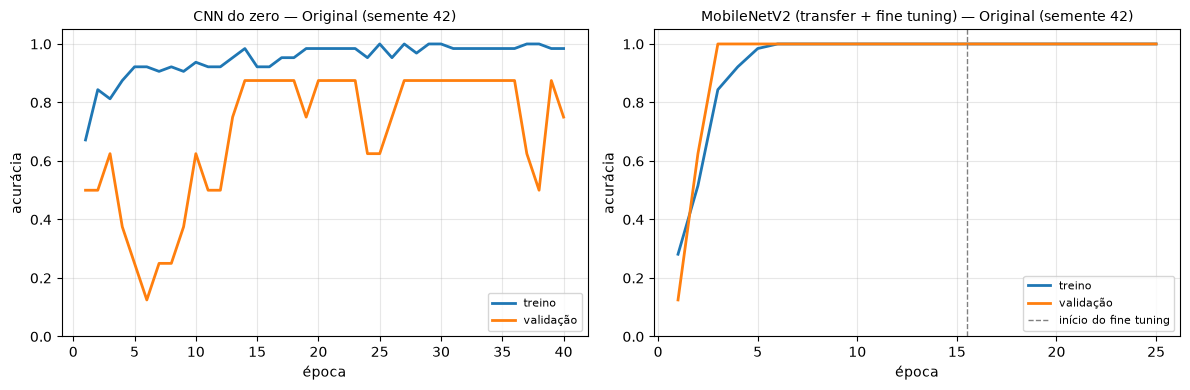

In [10]:
def plot_curves(ax: plt.Axes, history: History, title: str, boundary: int | None = None) -> None:
    epochs = np.arange(1, len(history["accuracy"]) + 1)
    ax.plot(epochs, history["accuracy"], label="treino", linewidth=2)
    ax.plot(epochs, history["val_accuracy"], label="validação", linewidth=2)
    if boundary:
        ax.axvline(boundary + 0.5, color="gray", linestyle="--", linewidth=1, label="início do fine tuning")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("época")
    ax.set_ylabel("acurácia")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")


def plot_learning_curves(variant: str, path: Path) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, model_name in zip(axes, TRAINERS):
        boundary = HEAD_EPOCHS if model_name == MODEL_TRANSFER else None
        title = f"{model_name} — {variant} (semente {SEEDS[0]})"
        plot_curves(ax, all_histories[(model_name, variant)][SEEDS[0]], title, boundary)
    fig.tight_layout()
    save_chart(fig, path)


plot_learning_curves(VARIANT_ORIGINAL, FIGURES_DIR / "curvas_original.png")

### Resultado da Parte A

Resume média ± desvio-padrão sobre as 3 sementes para as imagens originais (vírgula decimal).

In [11]:
METRICS = ["acc_treino", "acc_val", "acc_teste", "acc_val_teste", "logloss_val_teste", "tempo_treino_s", "inferencia_ms"]


def format_column(column: pd.Series) -> pd.Series:
    return column.map(lambda value: decimal(value, 3))


def summarize(rows: list[dict[str, Any]]) -> pd.DataFrame:
    grouped = pd.DataFrame(rows).groupby(["modelo", "imagens"], sort=False)[METRICS]
    mean, std = grouped.mean(), grouped.std()
    return mean.combine(std, lambda means, stds: format_column(means) + " ± " + format_column(stds))


summarize(all_rows)

,,acc_treino,acc_val,acc_teste,acc_val_teste,logloss_val_teste,tempo_treino_s,inferencia_ms
modelo,imagens,,,,,,,
CNN do zero,Original,"0,922 ± 0,083","0,708 ± 0,191","0,875 ± 0,125","0,792 ± 0,157","0,857 ± 0,523","57,584 ± 1,127","8,706 ± 0,613"
MobileNetV2 (transfer + fine tuning),Original,"1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","0,002 ± 0,001","35,119 ± 1,133","41,741 ± 0,834"


**Hipótese A — a rede pré-treinada supera a treinada do zero?** A conclusão com os números finais está na Parte C, e a Parte D a testa também fora do regime de teto. A expectativa teórica é que sim: com 64 imagens a CNN do zero precisa aprender filtros de borda, textura e forma sem dados suficientes, enquanto a MobileNetV2 já chega com esses filtros prontos.

---
## Parte B — Segmentação automática do objeto principal

### Estratégia (100% automática, igual para as duas classes)

1. **Detector de vocabulário aberto — YOLO-World (`yolov8x-worldv2`)** com os prompts de texto `"cow"` e `"tractor"`. O COCO não tem a classe *trator*, então um YOLO-seg comum só serviria para as vacas; o YOLO-World resolve as duas classes com o **mesmo** procedimento.
2. **SAM 2 (`sam2_b`)** recebe as caixas detectadas como *prompt* e devolve uma máscara precisa do contorno. A união das máscaras cobre rebanhos (várias vacas) e trator + implemento.
3. **A classe prevista pelo detector é descartada** — só a geometria (caixa) é usada, e as duas palavras são sempre enviadas juntas. Assim o rótulo não "vaza" diretamente para o classificador (ver limitações no fim).
4. **Fallback:** se não houver detecção com confiança ≥ 0,15 ou se a máscara cobrir menos de 2% da imagem, usa-se a imagem inteira. A contagem de fallbacks é reportada.

### Por que fundo preto?

* No pré-processamento da MobileNetV2 o preto vira `−1` e na CNN do zero vira `0`: um valor constante, sem textura, que gera pouca ativação nas convoluções — o modelo "vê" só o objeto.
* Fundo branco (`+1`) seria facilmente confundido com céu claro, neve ou partes brancas de vacas holandesas, criando bordas artificiais fortes no contorno.
* Fundo desfocado preservaria a cor do ambiente (verde do pasto, cinza do galpão), justamente o atalho que a segmentação quer remover. A Parte D mede o quanto esse atalho existe, classificando imagens **só com o fundo**.

### Carregamento do detector e do segmentador

Carrega o YOLO-World com o vocabulário fixo `cow`/`tractor` e o SAM 2, no dispositivo `TORCH_DEVICE`. Os pesos são baixados uma única vez para uma pasta de cache fora do projeto. O codificador de texto CLIP do YOLO-World normalmente seria baixado em `./weights/clip` (relativo à pasta atual, ou seja, dentro do repositório). Por isso a pasta de pesos do módulo `ultralytics.nn.text_model` é redirecionada para o mesmo cache, só nesta sessão e sem alterar as configurações globais do ultralytics. O redirecionamento só é aplicado se o módulo tiver esse atributo (testado na versão 8.4.175); em outra versão o notebook avisa e segue.

In [12]:
TEXT_MODEL_MODULE = "ultralytics.nn.text_model"
DETECTOR_WEIGHTS = "yolov8x-worldv2.pt"
SEGMENTER_WEIGHTS = "sam2_b.pt"
DETECTION_PROMPTS = ["cow", "tractor"]
MIN_CONFIDENCE = 0.15
MIN_MASK_FRACTION = 0.02
MAX_BOXES = 6


def redirect_clip_weights(folder: Path) -> None:
    module = importlib.import_module(TEXT_MODEL_MODULE) if importlib.util.find_spec(TEXT_MODEL_MODULE) else None
    if hasattr(module, "WEIGHTS_DIR"):
        module.WEIGHTS_DIR = folder
    else:
        print(f"Aviso: {TEXT_MODEL_MODULE}.WEIGHTS_DIR não existe nesta versão; o CLIP usará a pasta padrão do ultralytics.")


def load_segmenters() -> tuple[YOLOWorld, SAM]:
    redirect_clip_weights(WEIGHTS_DIR)
    detector = YOLOWorld(str(WEIGHTS_DIR / DETECTOR_WEIGHTS))
    detector.set_classes(DETECTION_PROMPTS)
    return detector, SAM(str(WEIGHTS_DIR / SEGMENTER_WEIGHTS))


detector, segmenter = load_segmenters()
print(f"Detector e segmentador carregados em {TORCH_DEVICE}")

Detector e segmentador carregados em cuda:0


### Funções de segmentação

`detect_boxes` devolve as caixas mais confiáveis (até 6); `segment_object` pede ao SAM 2 uma máscara por caixa e faz a união; `apply_mask` zera o fundo na imagem **original em resolução cheia**; `segment_image` aplica o fallback e devolve os metadados de cada imagem:

* nº de caixas e confiança máxima do detector;
* `area_mascara` (fração da imagem coberta pela máscara) e `area_caixas` (fração coberta pela união das caixas);
* `preenchimento` = máscara ÷ caixas. Sem rótulos de máscara verdadeiros não há IoU; o preenchimento é um indicador de qualidade sem rótulo: perto de 1 sugere que o SAM devolveu a própria caixa, e muito baixo sugere que ele pegou só uma parte do objeto;
* tempo de detecção e tempo do SAM 2, em ms, medidos separadamente.

In [13]:
def timed(function: Callable[..., Any], *args: Any) -> tuple[Any, float]:
    start = time.perf_counter()
    result = function(*args)
    return result, 1000 * (time.perf_counter() - start)


def detect_boxes(image_path: Path) -> tuple[np.ndarray, np.ndarray]:
    boxes = detector.predict(str(image_path), conf=MIN_CONFIDENCE, device=TORCH_DEVICE, verbose=False)[0].boxes
    order = boxes.conf.argsort(descending=True)[:MAX_BOXES]
    return boxes.xyxy[order].cpu().numpy(), boxes.conf[order].cpu().numpy()


def resize_mask(mask: np.ndarray, shape: tuple[int, int]) -> np.ndarray:
    if mask.shape == shape:
        return mask
    return np.asarray(Image.fromarray(mask).resize((shape[1], shape[0]), Image.NEAREST))


def segment_object(image_path: Path, boxes: np.ndarray, shape: tuple[int, int]) -> np.ndarray:
    masks = segmenter.predict(str(image_path), bboxes=boxes.tolist(), device=TORCH_DEVICE, verbose=False)[0].masks
    union = masks.data.any(dim=0).cpu().numpy().astype(np.uint8) * 255
    return resize_mask(union, shape) > 0


def boxes_area(boxes: np.ndarray, shape: tuple[int, int]) -> float:
    canvas = np.zeros(shape, bool)
    for x1, y1, x2, y2 in boxes.round().astype(int):
        canvas[y1:y2, x1:x2] = True
    return float(canvas.mean())


def timed_mask(image_path: Path, boxes: np.ndarray, shape: tuple[int, int]) -> tuple[np.ndarray, float]:
    if not len(boxes):
        return np.zeros(shape, bool), 0.0
    return timed(segment_object, image_path, boxes, shape)


def apply_mask(image: np.ndarray, mask: np.ndarray) -> np.ndarray:
    return image * mask[..., None].astype(image.dtype)


def segmentation_info(boxes: np.ndarray, confidences: np.ndarray, mask: np.ndarray, times: tuple[float, float]) -> dict[str, Any]:
    box_area = boxes_area(boxes, mask.shape)
    return {"caixas": len(boxes), "confianca_max": float(confidences.max()) if len(boxes) else 0.0,
            "area_mascara": float(mask.mean()), "area_caixas": box_area,
            "preenchimento": float(mask.mean()) / box_area if box_area else 0.0,
            "fallback": bool(mask.mean() < MIN_MASK_FRACTION),
            "tempo_deteccao_ms": times[0], "tempo_sam_ms": times[1]}


def segment_image(image_path: Path) -> tuple[np.ndarray, np.ndarray, np.ndarray, dict[str, Any]]:
    image = np.asarray(Image.open(image_path).convert("RGB"))
    (boxes, confidences), detection_ms = timed(detect_boxes, image_path)
    mask, sam_ms = timed_mask(image_path, boxes, image.shape[:2])
    info = segmentation_info(boxes, confidences, mask, (detection_ms, sam_ms))
    final_mask = np.ones_like(mask) if info["fallback"] else mask
    return image, final_mask, apply_mask(image, final_mask), info

### Segmentação do dataset inteiro

Percorre os 3 splits, salva a imagem segmentada (mesmo nome, em `SEGMENTED_DIR/<split>/`) e a máscara (`.png`, em `SEGMENTED_DIR/mascaras/<split>/`), e monta uma tabela com os metadados de cada imagem, resumida por classe. O tempo total inclui o aquecimento da primeira imagem; por isso os tempos por etapa são resumidos pela **mediana**.

In [14]:
MASKS_DIR = SEGMENTED_DIR / "mascaras"
QUALITY_COLUMNS = ["caixas", "confianca_max", "area_mascara", "area_caixas", "preenchimento", "fallback"]


def save_outputs(path: Path, split: str, mask: np.ndarray, masked: np.ndarray) -> None:
    for folder in (SEGMENTED_DIR / split, MASKS_DIR / split):
        folder.mkdir(parents=True, exist_ok=True)
    Image.fromarray(masked).save(SEGMENTED_DIR / split / path.name, quality=95)
    Image.fromarray(mask.astype(np.uint8) * 255).save(MASKS_DIR / split / f"{path.stem}.png")


def segment_dataset() -> pd.DataFrame:
    records = []
    for split in SPLITS:
        for path in list_images(DATASET_DIR, split):
            _, mask, masked, info = segment_image(path)
            save_outputs(path, split, mask, masked)
            records.append({"split": split, "arquivo": path.name, "classe": CLASSES[label_from_path(path)], **info})
    return pd.DataFrame(records)


start = time.perf_counter()
segmentation_report = segment_dataset()
segmentation_seconds = time.perf_counter() - start
fallbacks = segmentation_report[segmentation_report["fallback"]]
detection_median_ms = segmentation_report["tempo_deteccao_ms"].median()
sam_median_ms = segmentation_report["tempo_sam_ms"].median()
print(f"Segmentadas {len(segmentation_report)} imagens em {decimal(segmentation_seconds)} s "
      f"({decimal(1000 * segmentation_seconds / len(segmentation_report), 0)} ms/imagem, com aquecimento e gravação)")
print(f"Mediana por imagem: detecção {decimal(detection_median_ms, 0)} ms · SAM 2 {decimal(sam_median_ms, 0)} ms")
print(f"Fallbacks (imagem inteira): {len(fallbacks)} de {len(segmentation_report)}")
segmentation_report.groupby("classe")[QUALITY_COLUMNS].mean().style.format(precision=3, decimal=",")

Segmentadas 80 imagens em 17,6 s (220 ms/imagem, com aquecimento e gravação)
Mediana por imagem: detecção 34 ms · SAM 2 131 ms
Fallbacks (imagem inteira): 0 de 80


,caixas,confianca_max,area_mascara,area_caixas,preenchimento,fallback
classe,,,,,,
trator,"1,150","0,902","0,373","0,660","0,567","0,000"
vaca,"2,675","0,956","0,290","0,484","0,576","0,000"


### Qualidade das máscaras

À esquerda, a distribuição da área da máscara por classe: mostra quanto do quadro é objeto e quanto é fundo (quanto menor a área, mais fundo a segmentação remove). À direita, área das caixas × área da máscara: pontos na diagonal indicariam máscaras do tamanho da caixa (SAM sem efeito). Como vacas e tratores não são retângulos, o esperado é uma nuvem paralela à diagonal, abaixo dela; pontos isolados muito abaixo da nuvem indicariam máscaras que pegaram só parte do objeto. A tabela resume as mesmas grandezas por classe (mediana, mínimo e máximo).

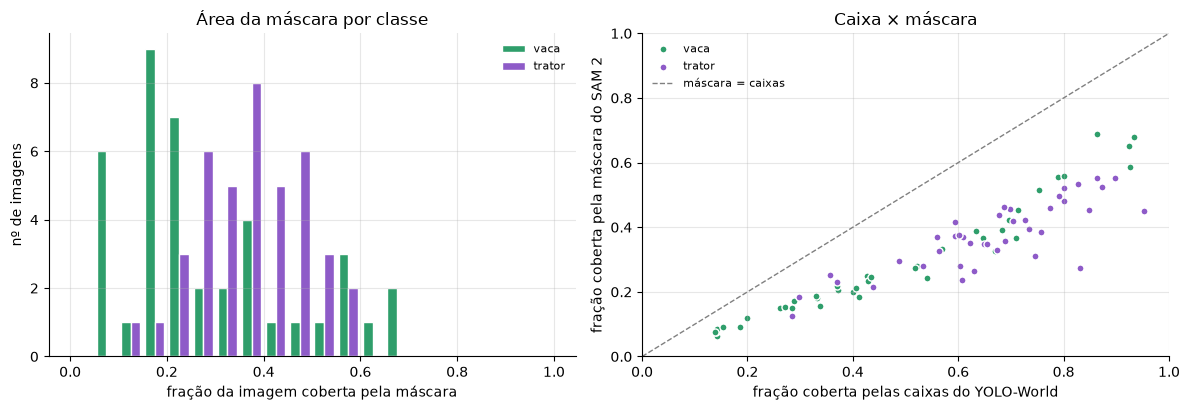

In [15]:
AREA_BINS = np.linspace(0, 1, 21)


def plot_segmentation_quality(path: Path) -> None:
    fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
    for name, color in CLASS_COLORS.items():
        subset = segmentation_report[segmentation_report["classe"] == name]
        right.scatter(subset["area_caixas"], subset["area_mascara"], color=color, s=26, edgecolor="white", label=name)
    left.hist([segmentation_report.loc[segmentation_report["classe"] == name, "area_mascara"] for name in CLASS_COLORS],
              AREA_BINS, color=list(CLASS_COLORS.values()), edgecolor="white", label=list(CLASS_COLORS))
    right.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="máscara = caixas")
    left.set(xlabel="fração da imagem coberta pela máscara", ylabel="nº de imagens", title="Área da máscara por classe")
    right.set(xlabel="fração coberta pelas caixas do YOLO-World", ylabel="fração coberta pela máscara do SAM 2",
              title="Caixa × máscara", xlim=(0, 1), ylim=(0, 1))
    for ax in (left, right):
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(fontsize=8, frameon=False)
    fig.tight_layout()
    save_chart(fig, path)


plot_segmentation_quality(FIGURES_DIR / "segmentacao_qualidade.png")
segmentation_report.groupby("classe")[["area_mascara", "preenchimento", "tempo_deteccao_ms", "tempo_sam_ms"]].agg(
    ["median", "min", "max"]).style.format(precision=2, decimal=",")

### Imagens em que a segmentação pode ter falhado

Lista as imagens que caíram no fallback (nenhuma detecção confiável ou máscara minúscula), as de menor confiança de detecção e as de menor preenchimento, que merecem inspeção visual.

In [16]:
REPORT_COLUMNS = ["split", "arquivo", "caixas", "confianca_max", "area_mascara", "preenchimento"]
SUSPECTS_PER_CRITERION = 5


def report_table(frame: pd.DataFrame) -> str:
    return frame[REPORT_COLUMNS].to_string(index=False, float_format=lambda value: decimal(value, 3))


print("Fallbacks:")
print(report_table(fallbacks) if len(fallbacks) else "nenhum")
print("\nMenor confiança de detecção:")
print(report_table(segmentation_report.nsmallest(SUSPECTS_PER_CRITERION, "confianca_max")))
print("\nMenor preenchimento (máscara ÷ caixas):")
print(report_table(segmentation_report.nsmallest(SUSPECTS_PER_CRITERION, "preenchimento")))

Fallbacks:
nenhum

Menor confiança de detecção:
split        arquivo  caixas  confianca_max  area_mascara  preenchimento
train trator_025.jpg       2          0,425         0,125          0,440
train trator_022.jpg       1          0,530         0,281          0,527
train trator_014.jpg       1          0,537         0,215          0,492
train trator_012.jpg       2          0,604         0,496          0,627
train trator_031.jpg       2          0,611         0,275          0,331

Menor preenchimento (máscara ÷ caixas):
split        arquivo  caixas  confianca_max  area_mascara  preenchimento
train trator_031.jpg       2          0,611         0,275          0,331
train trator_024.jpg       1          0,929         0,237          0,389
train trator_029.jpg       1          0,959         0,312          0,418
train trator_023.jpg       1          0,947         0,266          0,422
train trator_025.jpg       2          0,425         0,125          0,440


### Original | máscara | imagem segmentada

Mostra exemplos das duas classes, espalhados pelos splits, lendo os arquivos já salvos: a imagem original, a máscara binária gerada automaticamente e o resultado com fundo preto.

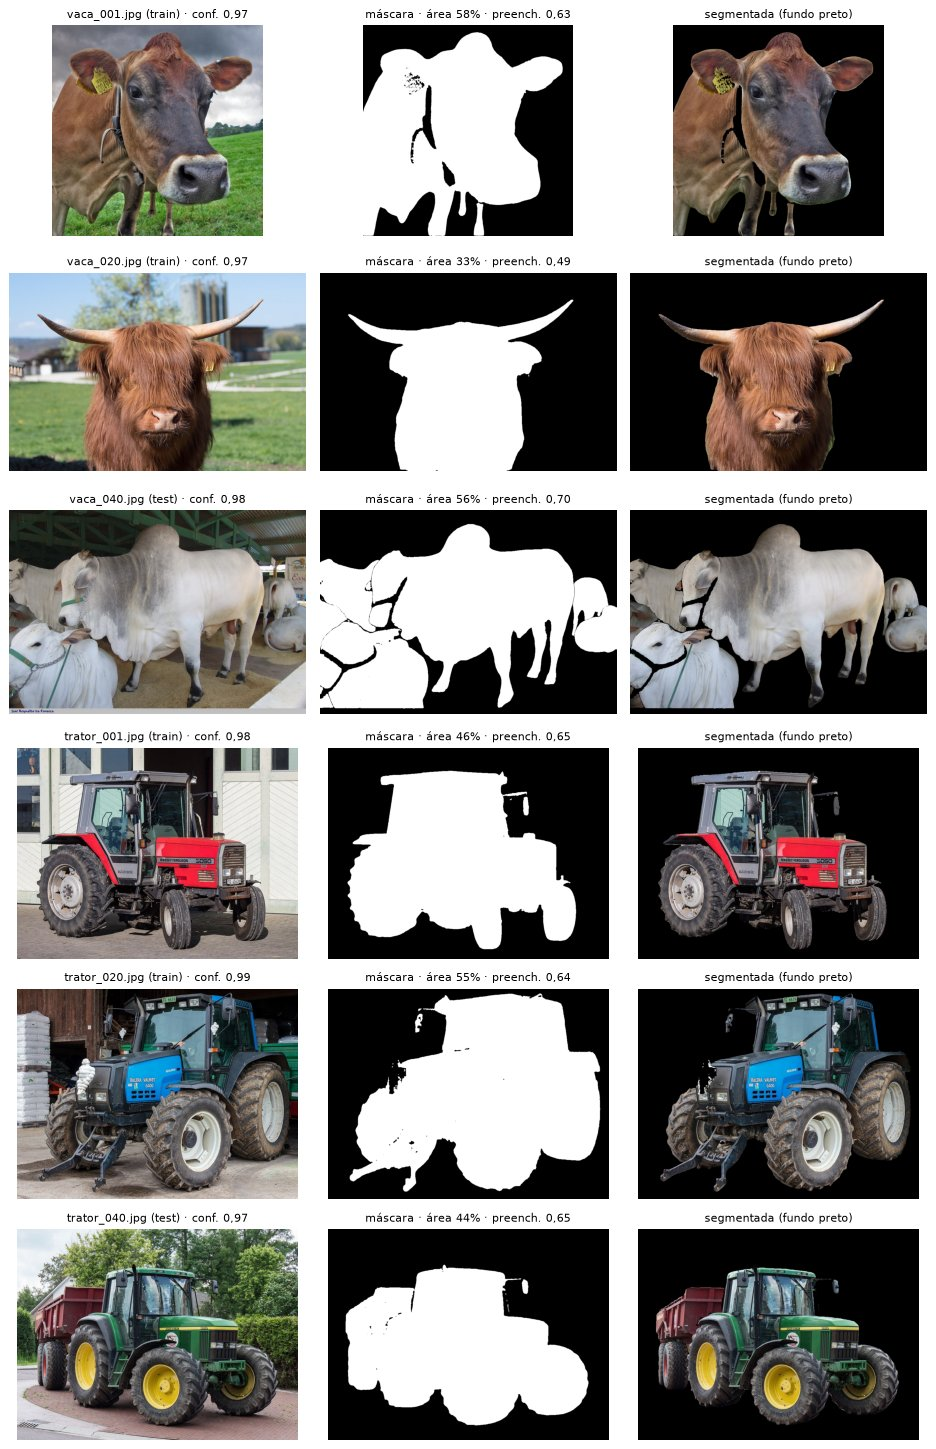

In [17]:
EXAMPLES_PER_CLASS = 3


def pick_examples() -> list[dict[str, Any]]:
    picks = []
    for name in CLASSES:
        subset = segmentation_report[segmentation_report["classe"] == name]
        picks += subset.iloc[np.linspace(0, len(subset) - 1, EXAMPLES_PER_CLASS).astype(int)].to_dict("records")
    return picks


def load_triplet(record: dict[str, Any]) -> list[Image.Image]:
    split, name = record["split"], record["arquivo"]
    mask_path = MASKS_DIR / split / f"{Path(name).stem}.png"
    return [Image.open(path) for path in (DATASET_DIR / split / name, mask_path, SEGMENTED_DIR / split / name)]


def triplet_titles(record: dict[str, Any]) -> tuple[str, str, str]:
    return (f"{record['arquivo']} ({record['split']}) · conf. {decimal(record['confianca_max'], 2)}",
            f"máscara · área {percent(record['area_mascara'], 0)} · preench. {decimal(record['preenchimento'], 2)}",
            "fallback: imagem inteira" if record["fallback"] else "segmentada (fundo preto)")


def plot_triplets(records: list[dict[str, Any]], path: Path) -> None:
    fig, axes = plt.subplots(len(records), 3, figsize=(10.5, 2.7 * len(records)), squeeze=False)
    for row, record in zip(axes, records):
        for ax, panel, title in zip(row, load_triplet(record), triplet_titles(record)):
            ax.imshow(panel, cmap="gray")
            ax.set_title(title, fontsize=8.5)
            ax.axis("off")
    fig.tight_layout()
    save_photo_grid(fig, path)


plot_triplets(pick_examples(), FIGURES_DIR / "segmentacao_exemplos.png")

### Casos difíceis

Mesmo formato, agora para as imagens mais suspeitas pelos critérios acima: as 2 de menor confiança de detecção, as 2 de menor área de máscara e as 2 de menor preenchimento (sem repetir imagens). É aqui que aparecem as falhas reais da segmentação automática.

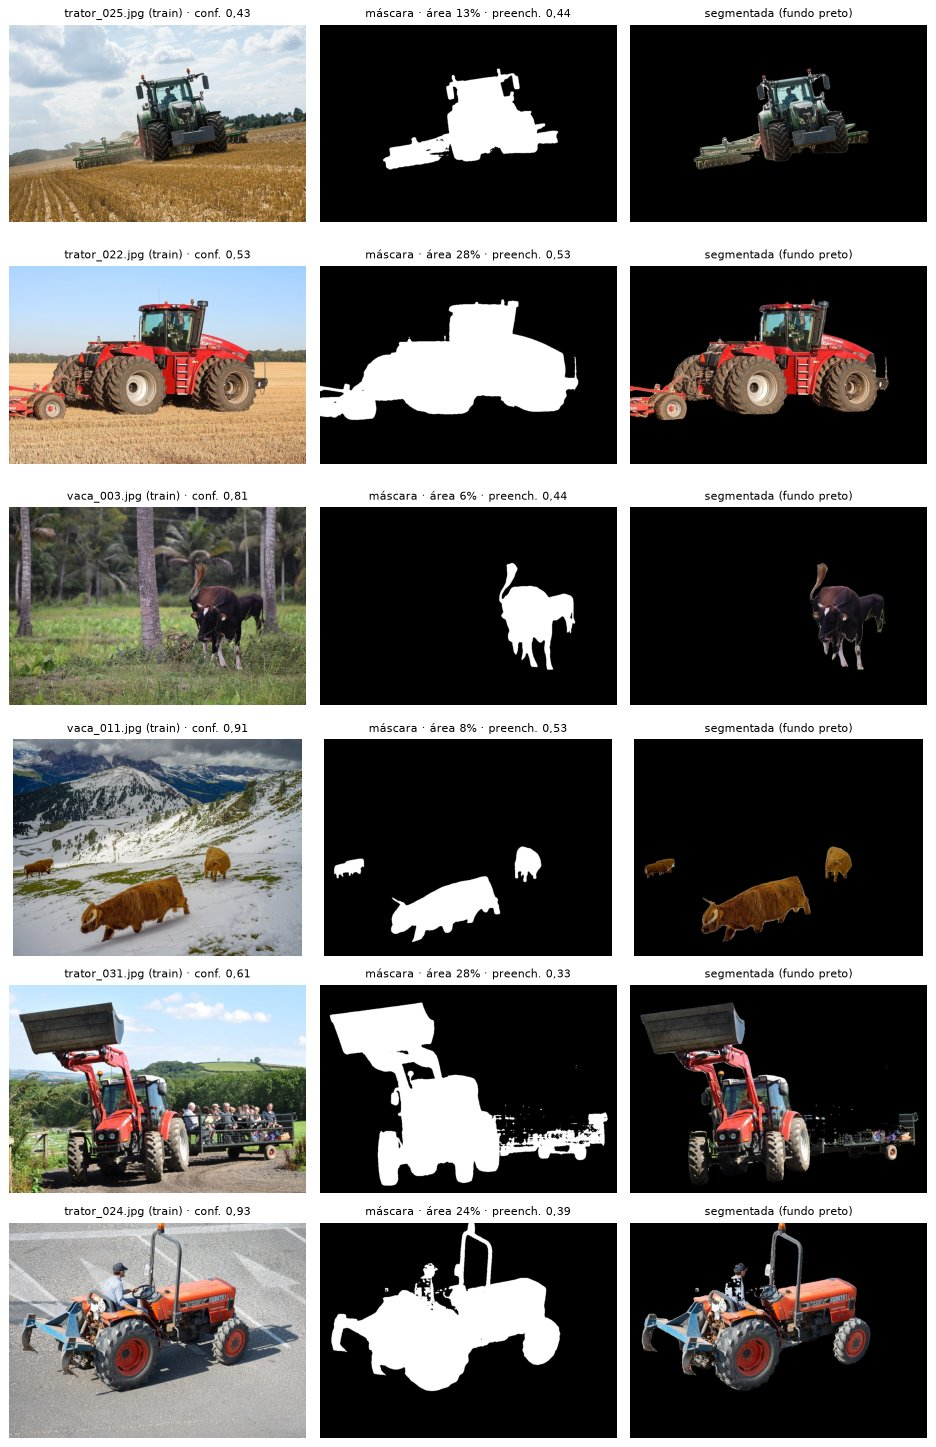

In [18]:
HARD_CASES_PER_CRITERION = 2
HARD_CASE_CRITERIA = ("confianca_max", "area_mascara", "preenchimento")


def pick_hard_cases() -> list[dict[str, Any]]:
    names = []
    for column in HARD_CASE_CRITERIA:
        ranked = segmentation_report.sort_values(column)["arquivo"]
        names += [name for name in ranked if name not in names][:HARD_CASES_PER_CRITERION]
    return segmentation_report.set_index("arquivo").loc[names].reset_index().to_dict("records")


plot_triplets(pick_hard_cases(), FIGURES_DIR / "segmentacao_casos_dificeis.png")

### Galeria completa das 80 imagens segmentadas

Para não esconder falhas, exibe todas as imagens segmentadas (título em vermelho = fallback).

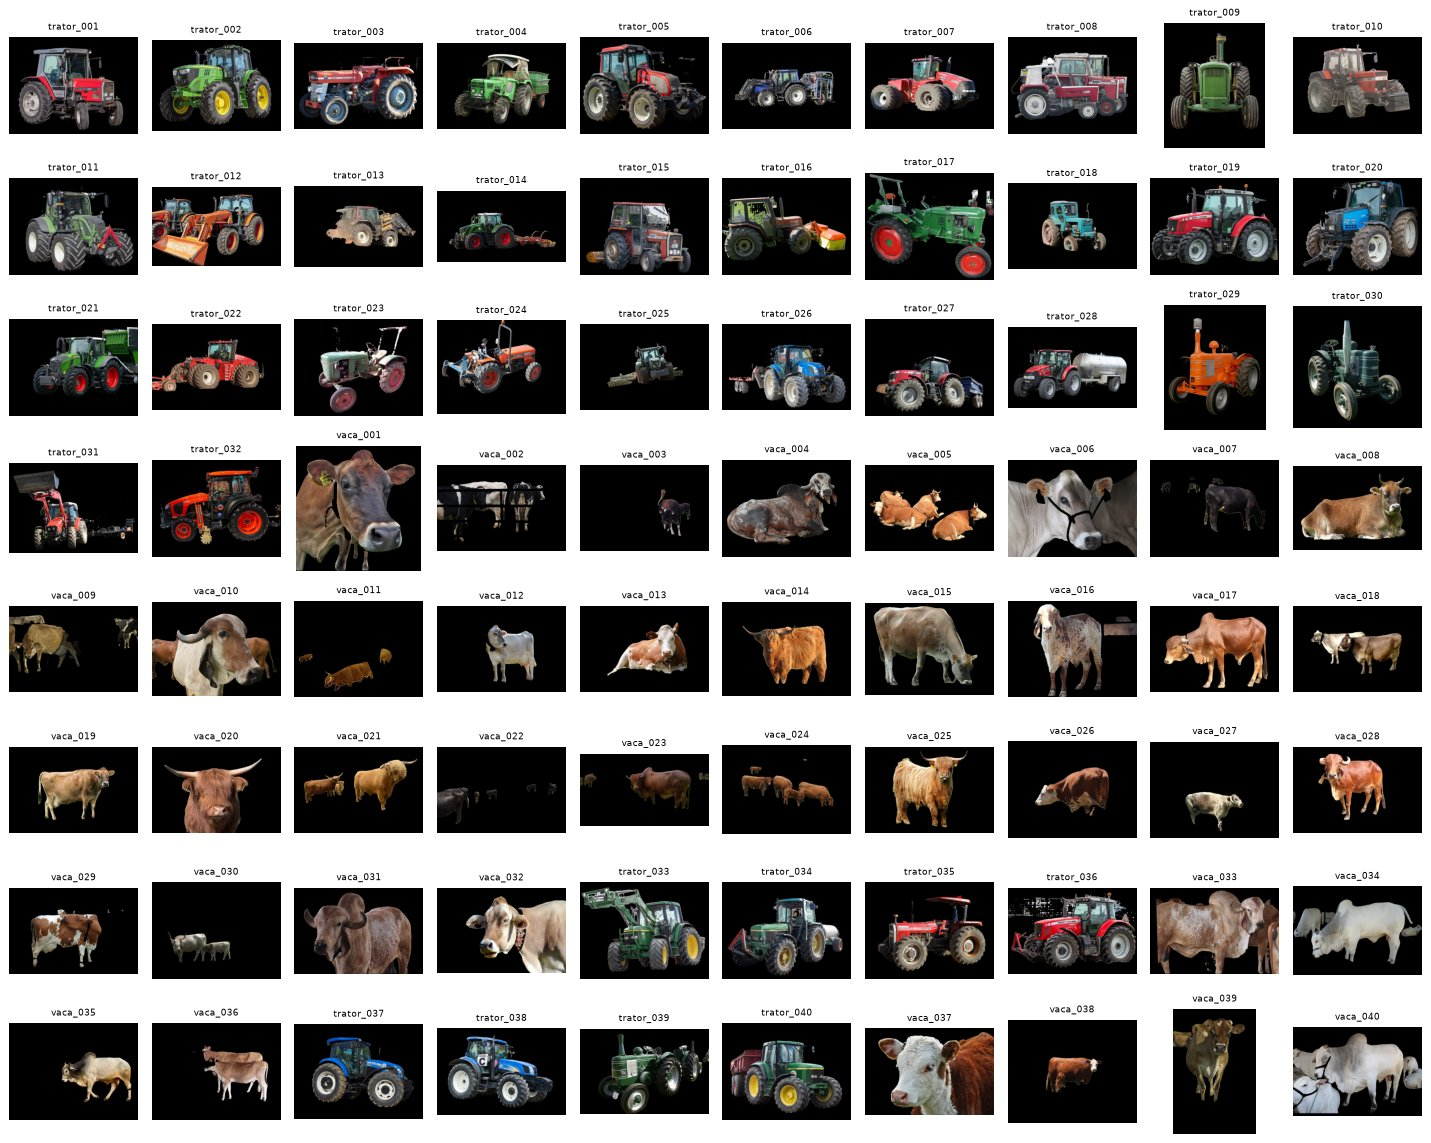

In [19]:
GALLERY_COLUMNS = 10


def plot_gallery(path: Path) -> None:
    rows = int(np.ceil(len(segmentation_report) / GALLERY_COLUMNS))
    fig, axes = plt.subplots(rows, GALLERY_COLUMNS, figsize=(GALLERY_COLUMNS * 1.6, rows * 1.6))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, record in zip(axes.ravel(), segmentation_report.to_dict("records")):
        ax.imshow(Image.open(SEGMENTED_DIR / record["split"] / record["arquivo"]))
        ax.set_title(Path(record["arquivo"]).stem, fontsize=7, color="red" if record["fallback"] else "black")
    fig.tight_layout()
    save_photo_grid(fig, path)


plot_gallery(FIGURES_DIR / "segmentacao_galeria.png")

### Treino nas imagens segmentadas

Libera a memória da GPU usada pelos modelos de segmentação, carrega o dataset segmentado (mesmos arquivos, mesmos splits) e repete exatamente o protocolo da Parte A: mesmos modelos, hiperparâmetros e sementes.

In [20]:
del detector, segmenter
torch.cuda.empty_cache()

segmented_data = load_dataset(SEGMENTED_DIR)
for model_name in TRAINERS:
    rows, histories = run_all_seeds(model_name, VARIANT_SEGMENTED, segmented_data)
    all_rows += rows
    all_histories[(model_name, VARIANT_SEGMENTED)] = histories

CNN do zero | Segmentada | semente 42: val 100,0% · teste 100,0% · val+teste 100,0% · treino 57 s


CNN do zero | Segmentada | semente 7: val 100,0% · teste 100,0% · val+teste 100,0% · treino 57 s


CNN do zero | Segmentada | semente 2024: val 100,0% · teste 100,0% · val+teste 100,0% · treino 57 s


MobileNetV2 (transfer + fine tuning) | Segmentada | semente 42: val 100,0% · teste 100,0% · val+teste 100,0% · treino 34 s


MobileNetV2 (transfer + fine tuning) | Segmentada | semente 7: val 100,0% · teste 100,0% · val+teste 100,0% · treino 34 s


MobileNetV2 (transfer + fine tuning) | Segmentada | semente 2024: val 100,0% · teste 100,0% · val+teste 100,0% · treino 35 s


### Curvas de aprendizado nas imagens segmentadas (semente 42)

Mesmo gráfico da Parte A, agora com fundo preto.

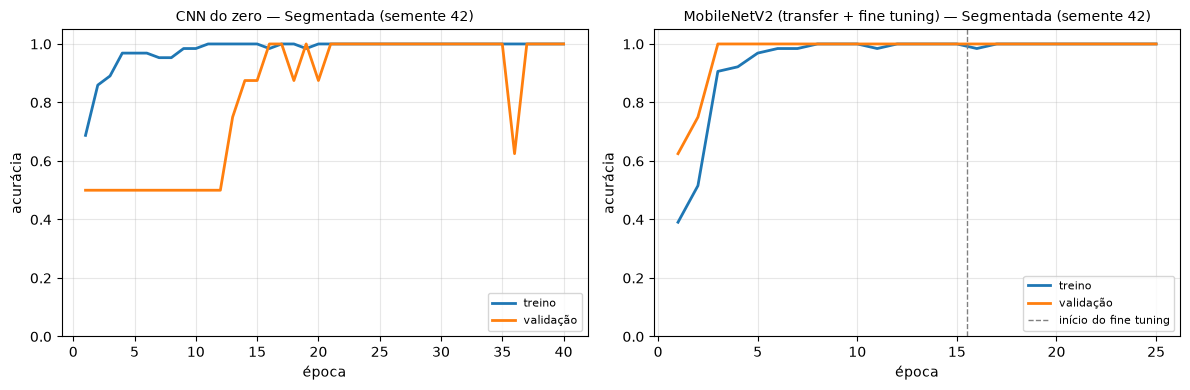

In [21]:
plot_learning_curves(VARIANT_SEGMENTED, FIGURES_DIR / "curvas_segmentada.png")

---
## Parte C — Comparação final

### Tabela das 4 combinações

Média ± desvio-padrão sobre as sementes 42, 7 e 2024. `acc_val_teste` junta validação e teste (16 imagens) para reduzir a granularidade: no teste puro cada erro vale 12,5 pontos percentuais. `logloss_val_teste` (entropia cruzada) diferencia modelos que acertam tudo mas com confiança diferente. Os tempos foram medidos no mesmo ambiente: treino e inferência no dispositivo `TF_DEVICE` impresso na célula de bibliotecas (CPU ou GPU, conforme a máquina); a inferência é por imagem, sobre o teste (8 imagens). A tabela também é salva em `figuras/comparacao_final.csv`.

In [22]:
results = pd.DataFrame(all_rows)
results.to_csv(FIGURES_DIR / "resultados_por_semente.csv", index=False)
final_table = summarize(all_rows)
final_table.to_csv(FIGURES_DIR / "comparacao_final.csv")
final_table

,,acc_treino,acc_val,acc_teste,acc_val_teste,logloss_val_teste,tempo_treino_s,inferencia_ms
modelo,imagens,,,,,,,
CNN do zero,Original,"0,922 ± 0,083","0,708 ± 0,191","0,875 ± 0,125","0,792 ± 0,157","0,857 ± 0,523","57,584 ± 1,127","8,706 ± 0,613"
MobileNetV2 (transfer + fine tuning),Original,"1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","0,002 ± 0,001","35,119 ± 1,133","41,741 ± 0,834"
CNN do zero,Segmentada,"0,995 ± 0,009","1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","0,008 ± 0,001","57,077 ± 0,434","9,075 ± 0,238"
MobileNetV2 (transfer + fine tuning),Segmentada,"1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","1,000 ± 0,000","0,001 ± 0,001","34,238 ± 0,512","39,459 ± 2,103"


### Resultados por semente

Mostra cada execução individual, para evidenciar a variância entre sementes. As colunas `*_cabeca` só existem para a MobileNetV2 (fim do estágio 1).

In [23]:
results.style.format(precision=3, decimal=",", na_rep="—")

,modelo,imagens,semente,tempo_treino_s,acc_treino,acc_val,acc_teste,acc_val_teste,logloss_val_teste,inferencia_ms,acc_val_teste_cabeca,logloss_val_teste_cabeca
0,CNN do zero,Original,42,"56,770","0,953","0,750","0,875","0,812","0,589","8,039",—,—
1,CNN do zero,Original,7,"57,113","0,984","0,875","1,000","0,938","0,523","8,837",—,—
2,CNN do zero,Original,2024,"58,871","0,828","0,500","0,750","0,625","1,459","9,243",—,—
3,MobileNetV2 (transfer + fine tuning),Original,42,"33,869","1,000","1,000","1,000","1,000","0,003","41,886","1,000","0,039"
4,MobileNetV2 (transfer + fine tuning),Original,7,"36,079","1,000","1,000","1,000","1,000","0,001","40,844","1,000","0,028"
5,MobileNetV2 (transfer + fine tuning),Original,2024,"35,408","1,000","1,000","1,000","1,000","0,001","42,493","1,000","0,027"
6,CNN do zero,Segmentada,42,"56,626","1,000","1,000","1,000","1,000","0,008","9,113",—,—
7,CNN do zero,Segmentada,7,"57,492","0,984","1,000","1,000","1,000","0,008","9,292",—,—
8,CNN do zero,Segmentada,2024,"57,112","1,000","1,000","1,000","1,000","0,009","8,820",—,—
9,MobileNetV2 (transfer + fine tuning),Segmentada,42,"33,724","1,000","1,000","1,000","1,000","0,001","37,997","1,000","0,020"


### Validação cruzada estratificada 5-fold (todas as 80 imagens)

Com 16 imagens de avaliação, cada erro move a acurácia em 6,25 p.p. Para uma estimativa menos frágil, junta treino+validação+teste (80 imagens) e roda **5-fold estratificado** (64 treino / 16 avaliação por fold, mesmas partições para as 4 combinações e para as duas versões das imagens). Cada imagem é avaliada exatamente uma vez por um modelo que não a viu. A versão segmentada usa os mesmos arquivos, na mesma ordem, de modo que a comparação é pareada. Além do resumo por fold, guarda a predição de **cada imagem** (`figuras/predicoes_validacao_cruzada.csv`), usada no teste de McNemar e na análise de erros abaixo.

In [24]:
CV_FOLDS = 5
CV_SEED = 42


def pool(data: Dataset) -> tuple[np.ndarray, np.ndarray, list[str]]:
    return (np.concatenate([data[split]["x"] for split in SPLITS]),
            np.concatenate([data[split]["y"] for split in SPLITS]),
            [path.name for split in SPLITS for path in data[split]["paths"]])


def fold_data(x: np.ndarray, y: np.ndarray, train_index: np.ndarray, eval_index: np.ndarray) -> Dataset:
    evaluation = {"x": x[eval_index], "y": y[eval_index]}
    return {"train": {"x": x[train_index], "y": y[train_index]}, "val": evaluation, "test": evaluation}


def fold_predictions(model: keras.Model, data: Dataset, names: list[str], eval_index: np.ndarray,
                     key: dict[str, Any]) -> list[dict[str, Any]]:
    probabilities = predict(model, data["test"]["x"])
    labels = data["test"]["y"].astype(int)
    return [{**key, "arquivo": names[index], "rotulo": int(label), "prob_trator": float(probability),
             "acerto": bool((probability > DECISION_THRESHOLD) == bool(label))}
            for index, label, probability in zip(eval_index, labels, probabilities)]


def run_cross_validation(model_name: str, variant: str, data: Dataset) -> tuple[list[dict[str, Any]], list[dict[str, Any]]]:
    x, y, names = pool(data)
    folds = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=CV_SEED).split(x, y)
    rows, predictions = [], []
    for fold, (train_index, eval_index) in enumerate(folds):
        split_data = fold_data(x, y, train_index, eval_index)
        row, _, model = run_experiment(model_name, variant, split_data, CV_SEED)
        rows.append({**row, "fold": fold, "acertos": round(row["acc_teste"] * len(eval_index)), "n": len(eval_index)})
        predictions += fold_predictions(model, split_data, names, eval_index, {"modelo": model_name, "imagens": variant, "fold": fold})
    total = sum(row["acertos"] for row in rows)
    print(f"{model_name} | {variant}: {total}/{len(y)} acertos ({percent(total / len(y))})")
    return rows, predictions


assert pool(original_data)[2] == pool(segmented_data)[2]
DATASETS = {VARIANT_ORIGINAL: original_data, VARIANT_SEGMENTED: segmented_data}
cv_rows, cv_prediction_rows = [], []
for variant, data in DATASETS.items():
    for model_name in TRAINERS:
        rows, predictions = run_cross_validation(model_name, variant, data)
        cv_rows += rows
        cv_prediction_rows += predictions

cv_results = pd.DataFrame(cv_rows)
cv_predictions = pd.DataFrame(cv_prediction_rows)
cv_results.to_csv(FIGURES_DIR / "validacao_cruzada.csv", index=False)
cv_predictions.to_csv(FIGURES_DIR / "predicoes_validacao_cruzada.csv", index=False)
cv_summary = cv_results.groupby(["modelo", "imagens"], sort=False).agg(
    acertos=("acertos", "sum"), n=("n", "sum"), acc_media_folds=("acc_teste", "mean"),
    acc_desvio_folds=("acc_teste", "std"), logloss_media=("logloss_val_teste", "mean"),
    tempo_treino_s=("tempo_treino_s", "mean"))
cv_summary["acc_total"] = cv_summary["acertos"] / cv_summary["n"]
cv_summary.style.format(precision=3, decimal=",")

CNN do zero | Original: 67/80 acertos (83,8%)


MobileNetV2 (transfer + fine tuning) | Original: 80/80 acertos (100,0%)


CNN do zero | Segmentada: 76/80 acertos (95,0%)


MobileNetV2 (transfer + fine tuning) | Segmentada: 80/80 acertos (100,0%)


,,acertos,n,acc_media_folds,acc_desvio_folds,logloss_media,tempo_treino_s,acc_total
modelo,imagens,,,,,,,
CNN do zero,Original,67,80,"0,838","0,095","1,259","59,167","0,838"
MobileNetV2 (transfer + fine tuning),Original,80,80,"1,000","0,000","0,002","37,810","1,000"
CNN do zero,Segmentada,76,80,"0,950","0,028","0,132","59,283","0,950"
MobileNetV2 (transfer + fine tuning),Segmentada,80,80,"1,000","0,000","0,002","38,404","1,000"


### Teste pareado de McNemar (validação cruzada)

Como as 4 combinações classificam **as mesmas 80 imagens**, a comparação certa é pareada: conta as imagens que só um dos dois modelos acerta e testa, com o **teste exato de McNemar** (binomial sobre os pares discordantes), se essa assimetria poderia ser acaso. Imagens que os dois acertam (ou os dois erram) não informam nada sobre a diferença. Ressalva: os folds compartilham dados de treino, então as predições não são totalmente independentes; o p-valor é indicativo, não exato.

In [25]:
MCNEMAR_PAIRS = (
    ((MODEL_SCRATCH, VARIANT_ORIGINAL), (MODEL_TRANSFER, VARIANT_ORIGINAL)),
    ((MODEL_SCRATCH, VARIANT_ORIGINAL), (MODEL_SCRATCH, VARIANT_SEGMENTED)),
    ((MODEL_TRANSFER, VARIANT_ORIGINAL), (MODEL_TRANSFER, VARIANT_SEGMENTED)),
    ((MODEL_SCRATCH, VARIANT_SEGMENTED), (MODEL_TRANSFER, VARIANT_SEGMENTED)),
)


def correctness(model_name: str, variant: str) -> pd.Series:
    rows = cv_predictions[(cv_predictions["modelo"] == model_name) & (cv_predictions["imagens"] == variant)]
    return rows.set_index("arquivo")["acerto"].sort_index()


def mcnemar(first: tuple[str, str], second: tuple[str, str]) -> dict[str, Any]:
    a, b = correctness(*first), correctness(*second)
    only_first, only_second = int((a & ~b).sum()), int((~a & b).sum())
    discordant = only_first + only_second
    p = binomtest(min(only_first, only_second), discordant, 0.5).pvalue if discordant else 1.0
    return {"A": f"{first[0]} · {first[1].lower()}", "B": f"{second[0]} · {second[1].lower()}",
            "só A acerta": only_first, "só B acerta": only_second, "p (McNemar exato)": p}


mcnemar_table = pd.DataFrame([mcnemar(*pair) for pair in MCNEMAR_PAIRS])
mcnemar_table.style.format({"p (McNemar exato)": p_value})

,A,B,só A acerta,só B acerta,p (McNemar exato)
0,CNN do zero · original,MobileNetV2 (transfer + fine tuning) · original,0,13,"< 0,001"
1,CNN do zero · original,CNN do zero · segmentada,3,12,"0,035"
2,MobileNetV2 (transfer + fine tuning) · original,MobileNetV2 (transfer + fine tuning) · segmentada,0,0,"1,000"
3,CNN do zero · segmentada,MobileNetV2 (transfer + fine tuning) · segmentada,0,4,"0,125"


### O que o fine tuning (estágio 2) acrescentou?

Compara, na validação cruzada, a MobileNetV2 ao fim do estágio 1 (só a cabeça treinada, base congelada) e ao fim do estágio 2 (fine tuning a partir de `block_15_expand`). Se a acurácia já é máxima no estágio 1, o ganho do fine tuning só pode aparecer na confiança das predições (log-loss).

In [26]:
def fine_tuning_effect() -> pd.DataFrame:
    transfer = cv_results[cv_results["modelo"] == MODEL_TRANSFER]
    return transfer.groupby("imagens", sort=False).agg(
        acc_estagio1=("acc_val_teste_cabeca", "mean"), acc_estagio2=("acc_teste", "mean"),
        logloss_estagio1=("logloss_val_teste_cabeca", "mean"), logloss_estagio2=("logloss_val_teste", "mean"))


fine_tuning_table = fine_tuning_effect()
fine_tuning_table.style.format(precision=4, decimal=",")

,acc_estagio1,acc_estagio2,logloss_estagio1,logloss_estagio2
imagens,,,,
Original,"1,0000","1,0000","0,0354","0,0019"
Segmentada,"1,0000","1,0000","0,0235","0,0015"


### Onde a CNN do zero erra nas imagens originais?

Junta as predições da validação cruzada com os metadados da segmentação. Se os erros se concentram em imagens com **objeto pequeno** (pouca área de máscara, muito fundo), isso sustenta a explicação de que a CNN do zero se apoia no fundo e de que a segmentação ajuda justamente por removê-lo. A galeria mostra as imagens erradas, com a probabilidade de "trator" prevista, a área da máscara e se a mesma CNN acertou a versão segmentada.

Erros da CNN do zero (originais, CV): 13 de 80 · por classe: {'vaca': 10, 'trator': 3}
Área mediana da máscara: 24% nos erros · 36% nos acertos


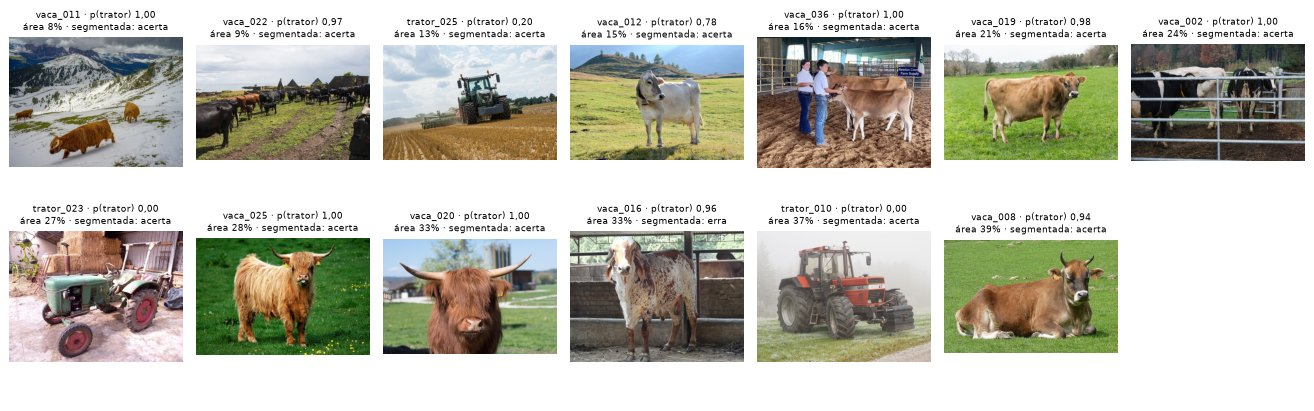

In [27]:
ERROR_COLUMNS = 7


def error_analysis() -> pd.DataFrame:
    original = cv_predictions[(cv_predictions["modelo"] == MODEL_SCRATCH) & (cv_predictions["imagens"] == VARIANT_ORIGINAL)]
    segmented = correctness(MODEL_SCRATCH, VARIANT_SEGMENTED).rename("acerto_segmentada")
    merged = original.merge(segmentation_report[["arquivo", "split", "classe", "area_mascara"]], on="arquivo")
    return merged.merge(segmented, left_on="arquivo", right_index=True)


def plot_error_gallery(errors: pd.DataFrame, path: Path) -> None:
    rows = int(np.ceil(len(errors) / ERROR_COLUMNS))
    fig, axes = plt.subplots(rows, ERROR_COLUMNS, figsize=(ERROR_COLUMNS * 2.1, rows * 2.4), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, record in zip(axes.ravel(), errors.to_dict("records")):
        ax.imshow(Image.open(DATASET_DIR / record["split"] / record["arquivo"]))
        verdict = "acerta" if record["acerto_segmentada"] else "erra"
        ax.set_title(f"{Path(record['arquivo']).stem} · p(trator) {decimal(record['prob_trator'], 2)}\n"
                     f"área {percent(record['area_mascara'], 0)} · segmentada: {verdict}", fontsize=7.5)
    fig.tight_layout()
    save_photo_grid(fig, path)


scratch_analysis = error_analysis()
scratch_errors = scratch_analysis[~scratch_analysis["acerto"]].sort_values("area_mascara")
area_by_outcome = scratch_analysis.groupby("acerto")["area_mascara"].median()
print(f"Erros da CNN do zero (originais, CV): {len(scratch_errors)} de {len(scratch_analysis)} "
      f"· por classe: {scratch_errors['classe'].value_counts().to_dict()}")
print(f"Área mediana da máscara: {percent(area_by_outcome.get(False, np.nan), 0)} nos erros · "
      f"{percent(area_by_outcome.get(True, np.nan), 0)} nos acertos")
if len(scratch_errors):
    plot_error_gallery(scratch_errors, FIGURES_DIR / "erros_cnn_do_zero.png")

### Gráfico comparativo

À esquerda, acurácia média em validação+teste (16 imagens) sobre as 3 sementes. À direita, acurácia da validação cruzada 5-fold sobre as 80 imagens. A altura da barra é a média. **A barra de erro vai do mínimo ao máximo** entre sementes (esquerda) ou folds (direita), e não ± desvio-padrão, que poderia ultrapassar 100%. Os pontos são as execuções individuais.

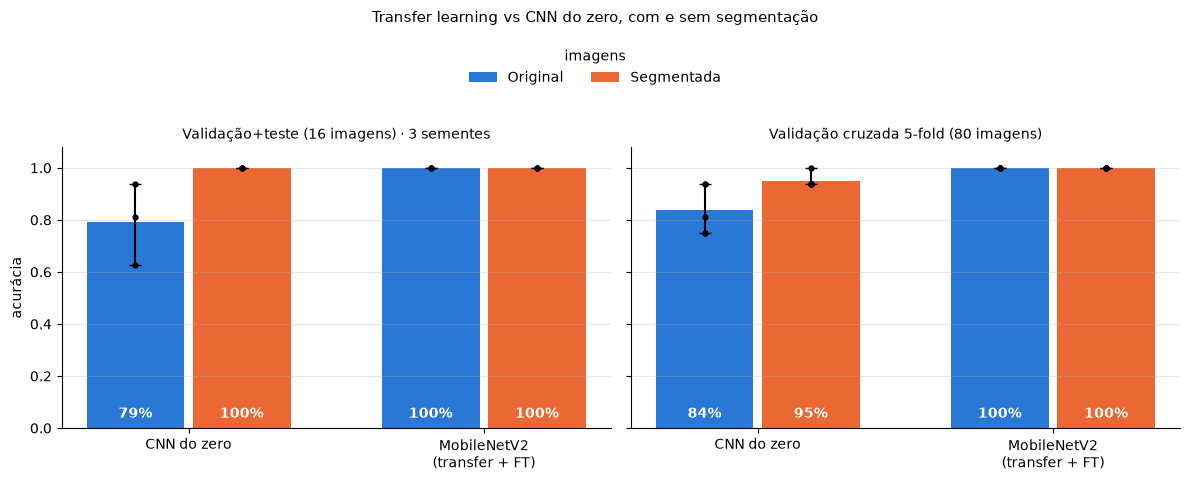

In [28]:
BAR_WIDTH = 0.36
BAR_VARIANTS = (VARIANT_ORIGINAL, VARIANT_SEGMENTED)


def draw_bars(ax: plt.Axes, frame: pd.DataFrame, metric: str, title: str) -> None:
    for offset, variant in zip((-BAR_WIDTH / 2, BAR_WIDTH / 2), BAR_VARIANTS):
        for position, model_name in enumerate(TRAINERS):
            values = frame[(frame["modelo"] == model_name) & (frame["imagens"] == variant)][metric]
            center = position + offset
            spread = [[values.mean() - values.min()], [values.max() - values.mean()]]
            ax.bar(center, values.mean(), BAR_WIDTH * 0.92, yerr=spread, color=VARIANT_COLORS[variant], capsize=4,
                   label=variant if position == 0 else None)
            ax.scatter([center] * len(values), values, color="black", s=12, zorder=3)
            ax.text(center, 0.04, percent(values.mean(), 0), ha="center", color="white", fontsize=10, fontweight="bold")
    ax.set_xticks(range(len(TRAINERS)), ["CNN do zero", "MobileNetV2\n(transfer + FT)"])
    ax.set_ylim(0, 1.08)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)


def plot_comparison(path: Path) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    draw_bars(axes[0], results, "acc_val_teste", f"Validação+teste (16 imagens) · {len(SEEDS)} sementes")
    draw_bars(axes[1], cv_results, "acc_teste", f"Validação cruzada {CV_FOLDS}-fold (80 imagens)")
    axes[0].set_ylabel("acurácia")
    fig.suptitle("Transfer learning vs CNN do zero, com e sem segmentação", fontsize=11, y=1.06)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="imagens", loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    save_chart(fig, path)


plot_comparison(FIGURES_DIR / "comparacao_final.png")

---
## Parte D — Além do teto: sondagem linear com poucas imagens por classe

### Por que esta parte existe

Com 64 imagens de treino a MobileNetV2 acerta 100% com e sem segmentação. Esse **efeito de teto** deixa a hipótese B sem resposta para ela (não há erro para a segmentação corrigir) e mede a hipótese A num único ponto, o mais fácil. Para tornar as duas hipóteses mensuráveis, sem retreinar redes, esta parte faz uma **sondagem linear** (*linear probe*):

1. Cada imagem passa uma única vez por uma MobileNetV2 congelada, e o vetor de 1280 características do *global average pooling* é guardado.
2. Uma regressão logística é treinada com apenas **k imagens por classe** (k = 1, 2, 4, 8, 16, 32) e avaliada em **todas as demais** das 80 imagens. Cada k é repetido em 50 sorteios; os mesmos sorteios valem para todas as variantes, então as comparações são pareadas.
3. As características são centradas pela média do próprio treino e normalizadas para norma 1, o padrão de sondagens *few-shot* (não usa nenhuma estatística das imagens de avaliação).

**Duas redes, mesma arquitetura:** pesos **ImageNet** e pesos **aleatórios** (sem pré-treino). A diferença entre elas isola o efeito do pré-treino (hipótese A) sem confundir com arquitetura, épocas ou aumento de dados.

**Três versões das imagens:** original, segmentada (fundo preto) e **só fundo**, em que o retângulo que envolve a máscara é pintado de preto. Se um classificador acerta muito acima de 50% vendo só o fundo, o fundo é um atalho real, e removê-lo (hipótese B) tem fundamento. O retângulo, e não a silhueta, é usado para não entregar a forma do objeto; o tamanho e a posição do retângulo ainda vazam um pouco de informação, o que torna essa medida um limite superior do poder do fundo.

Custo: 480 passadas de inferência e 1.800 regressões logísticas, segundos na CPU.

### Imagens "só fundo" e extração de características

Monta as imagens só com o fundo a partir das máscaras salvas (redimensionadas para 224×224), extrai as características das três versões com as duas redes e informa quanto do quadro sobra como fundo, em média.

In [29]:
PROBE_SEED = 42
FEATURES_IMAGENET = "ImageNet"
FEATURES_RANDOM = "aleatórios"


def load_small_mask(split: str, path: Path) -> np.ndarray:
    mask = Image.open(MASKS_DIR / split / f"{path.stem}.png").resize((IMG_SIZE, IMG_SIZE), Image.NEAREST)
    return np.asarray(mask) > 0


def cover_object(image: np.ndarray, mask: np.ndarray) -> np.ndarray:
    rows, columns = np.where(mask.any(axis=1))[0], np.where(mask.any(axis=0))[0]
    covered = image.copy()
    covered[rows[0]:rows[-1] + 1, columns[0]:columns[-1] + 1] = 0
    return covered


def background_only(data: Dataset) -> np.ndarray:
    return np.stack([cover_object(image, load_small_mask(split, path))
                     for split in SPLITS for image, path in zip(data[split]["x"], data[split]["paths"])])


def build_random_base() -> keras.Model:
    keras.backend.clear_session()
    keras.utils.set_random_seed(PROBE_SEED)
    return build_mobilenet_base(weights=None)


def extract_features(base: keras.Model, x: np.ndarray) -> np.ndarray:
    batches = [base(mobilenet_v2.preprocess_input(x[start:start + BATCH_SIZE].copy()), training=False)
               for start in range(0, len(x), BATCH_SIZE)]
    return np.concatenate([batch.numpy().mean(axis=(1, 2)) for batch in batches])


probe_images = {VARIANT_ORIGINAL: pool(original_data)[0], VARIANT_SEGMENTED: pool(segmented_data)[0],
                VARIANT_BACKGROUND: background_only(original_data)}
probe_labels = pool(original_data)[1].astype(int)
probe_bases = {FEATURES_RANDOM: build_random_base(), FEATURES_IMAGENET: build_mobilenet_base()}
probe_features = {(features, variant): extract_features(base, images)
                  for features, base in probe_bases.items() for variant, images in probe_images.items()}
background_fraction = float((probe_images[VARIANT_BACKGROUND].sum(axis=-1) > 0).mean())
print(f"Características extraídas: {len(probe_features)} conjuntos de {probe_features[(FEATURES_IMAGENET, VARIANT_ORIGINAL)].shape}")
print(f"Fração média do quadro que sobra nas imagens 'só fundo': {percent(background_fraction)}")

Características extraídas: 6 conjuntos de (80, 1280)
Fração média do quadro que sobra nas imagens 'só fundo': 40,8%


### Sondagem com k imagens por classe

Para cada k e cada sorteio, escolhe k imagens de cada classe para treino (sementes fixas), treina a regressão logística em cada um dos 6 conjuntos de características e mede a acurácia nas imagens restantes. A tabela mostra a acurácia média; o CSV `figuras/sondagem_k_shot.csv` guarda todos os sorteios.

In [30]:
PROBE_SHOTS = (1, 2, 4, 8, 16, 32)
PROBE_DRAWS = 50
PROBE_REGULARIZATION = 1.0
PROBE_MAX_ITER = 2000


def draw_split(shots: int, draw: int) -> tuple[np.ndarray, np.ndarray]:
    rng = np.random.default_rng([PROBE_SEED, shots, draw])
    train = np.concatenate([rng.choice(np.flatnonzero(probe_labels == label), shots, replace=False)
                            for label in range(len(CLASSES))])
    return train, np.setdiff1d(np.arange(len(probe_labels)), train)


def unit_rows(features: np.ndarray, center: np.ndarray) -> np.ndarray:
    centered = features - center
    return centered / np.linalg.norm(centered, axis=1, keepdims=True)


def center_and_normalize(train: np.ndarray, evaluation: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    center = train.mean(axis=0)
    return unit_rows(train, center), unit_rows(evaluation, center)


def probe_accuracy(features: np.ndarray, train: np.ndarray, evaluation: np.ndarray) -> float:
    train_x, eval_x = center_and_normalize(features[train], features[evaluation])
    classifier = LogisticRegression(C=PROBE_REGULARIZATION, max_iter=PROBE_MAX_ITER).fit(train_x, probe_labels[train])
    return float((classifier.predict(eval_x) == probe_labels[evaluation]).mean())


def run_probe() -> pd.DataFrame:
    rows = []
    for shots in PROBE_SHOTS:
        for draw in range(PROBE_DRAWS):
            train, evaluation = draw_split(shots, draw)
            rows += [{"caracteristicas": features, "imagens": variant, "k": shots, "sorteio": draw,
                      "acuracia": probe_accuracy(values, train, evaluation)}
                     for (features, variant), values in probe_features.items()]
    return pd.DataFrame(rows)


start = time.perf_counter()
probe_results = run_probe()
probe_seconds = time.perf_counter() - start
probe_results.to_csv(FIGURES_DIR / "sondagem_k_shot.csv", index=False)
print(f"{len(probe_results)} regressões logísticas em {decimal(probe_seconds)} s")
probe_results.pivot_table(index="k", columns=["caracteristicas", "imagens"], values="acuracia").style.format(percent)

1800 regressões logísticas em 6,0 s


### Curvas de acurácia × imagens de treino por classe

Três perguntas, um painel cada (mesmo eixo y). A linha é a média dos 50 sorteios e a faixa vai do percentil 2,5 ao 97,5. Cor = versão da imagem; linha cheia = pesos ImageNet; tracejada = pesos aleatórios. A linha pontilhada marca o acaso (50%).

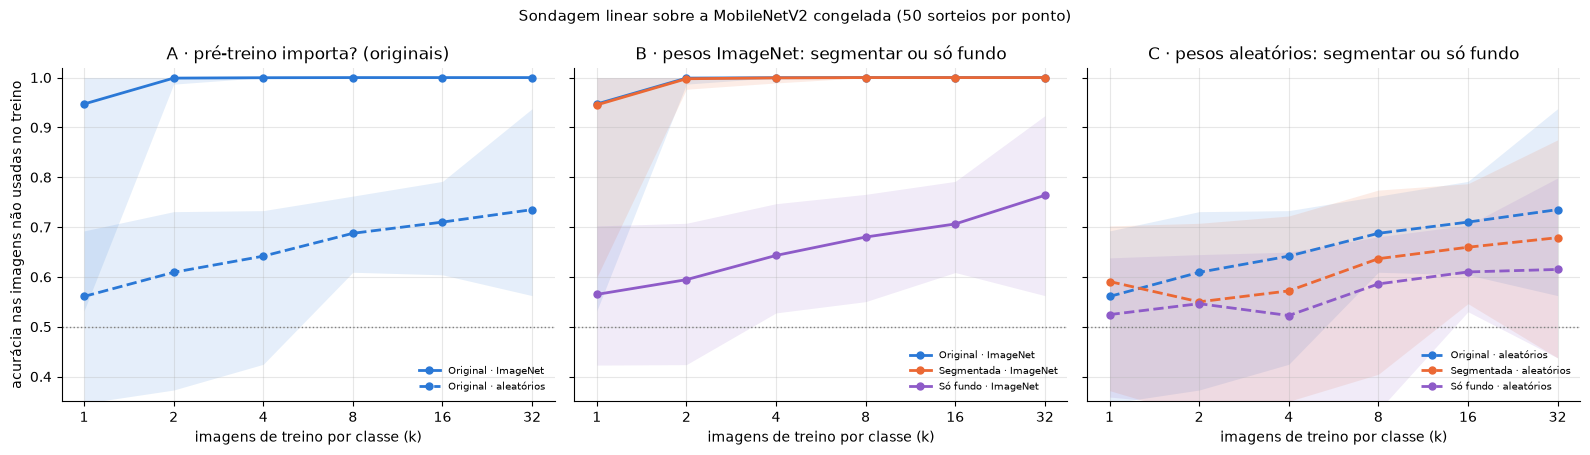

In [31]:
FEATURE_STYLES = {FEATURES_IMAGENET: "-", FEATURES_RANDOM: "--"}
PROBE_PANELS = (
    ("A · pré-treino importa? (originais)", [(FEATURES_IMAGENET, VARIANT_ORIGINAL), (FEATURES_RANDOM, VARIANT_ORIGINAL)]),
    ("B · pesos ImageNet: segmentar ou só fundo", [(FEATURES_IMAGENET, variant) for variant in probe_images]),
    ("C · pesos aleatórios: segmentar ou só fundo", [(FEATURES_RANDOM, variant) for variant in probe_images]),
)
CHANCE = 1 / len(CLASSES)
BAND = ((1 - CONFIDENCE_LEVEL) / 2, 1 - (1 - CONFIDENCE_LEVEL) / 2)


def probe_curve(features: str, variant: str) -> pd.DataFrame:
    rows = probe_results[(probe_results["caracteristicas"] == features) & (probe_results["imagens"] == variant)]
    grouped = rows.groupby("k")["acuracia"]
    return pd.DataFrame({"media": grouped.mean(), "baixo": grouped.quantile(BAND[0]), "alto": grouped.quantile(BAND[1])})


def draw_probe_panel(ax: plt.Axes, title: str, series: list[tuple[str, str]]) -> None:
    for features, variant in series:
        curve, color = probe_curve(features, variant), VARIANT_COLORS[variant]
        ax.fill_between(curve.index, curve["baixo"], curve["alto"], color=color, alpha=0.12, linewidth=0)
        ax.plot(curve.index, curve["media"], FEATURE_STYLES[features], color=color, marker="o", markersize=5,
                linewidth=2, label=f"{variant} · {features}")
    ax.axhline(CHANCE, color="gray", linestyle=":", linewidth=1)
    ax.set_xscale("log", base=2)
    ax.set_xticks(PROBE_SHOTS, [str(shots) for shots in PROBE_SHOTS])
    ax.set(title=title, xlabel="imagens de treino por classe (k)", ylim=(0.35, 1.02))
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=7.5, loc="lower right", frameon=False)


def plot_probe(path: Path) -> None:
    fig, axes = plt.subplots(1, len(PROBE_PANELS), figsize=(16, 4.6), sharey=True)
    for ax, (title, series) in zip(axes, PROBE_PANELS):
        draw_probe_panel(ax, title, series)
    axes[0].set_ylabel("acurácia nas imagens não usadas no treino")
    fig.suptitle(f"Sondagem linear sobre a MobileNetV2 congelada ({PROBE_DRAWS} sorteios por ponto)", fontsize=11)
    fig.tight_layout()
    save_chart(fig, path)


plot_probe(FIGURES_DIR / "sondagem_k_shot.png")

### Efeito pareado da segmentação na sondagem

Para cada k, compara a mesma regressão logística, nos mesmos sorteios, com imagens segmentadas e originais: diferença média de acurácia (segmentada − original) e em quantos dos 50 sorteios a segmentada foi melhor ou pior.

In [32]:
def paired_segmentation_effect(features: str) -> pd.DataFrame:
    rows = probe_results[probe_results["caracteristicas"] == features]
    wide = rows.pivot_table(index=["k", "sorteio"], columns="imagens", values="acuracia")
    difference = wide[VARIANT_SEGMENTED] - wide[VARIANT_ORIGINAL]
    grouped = difference.groupby("k")
    return pd.DataFrame({"caracteristicas": features, "diferenca_media": grouped.mean(),
                         "sorteios_melhor": grouped.apply(lambda values: int((values > 0).sum())),
                         "sorteios_pior": grouped.apply(lambda values: int((values < 0).sum()))})


segmentation_probe_effect = pd.concat([paired_segmentation_effect(features) for features in probe_bases])
segmentation_probe_effect.style.format({"diferenca_media": lambda value: f"{decimal(100 * value)} p.p."})

,caracteristicas,diferenca_media,sorteios_melhor,sorteios_pior
k,,,,
1,aleatórios,"3,0 p.p.",31,16
2,aleatórios,"-5,9 p.p.",17,33
4,aleatórios,"-7,0 p.p.",11,33
8,aleatórios,"-5,1 p.p.",15,33
16,aleatórios,"-5,0 p.p.",12,32
32,aleatórios,"-5,6 p.p.",18,29
1,ImageNet,"-0,2 p.p.",13,18
2,ImageNet,"-0,1 p.p.",1,4
4,ImageNet,"-0,0 p.p.",1,2


---
## Conclusões

### Conclusões numéricas (geradas a partir dos resultados)

A célula abaixo monta a tabela final e os vereditos das hipóteses **a partir dos DataFrames desta execução** (`results`, `cv_results`, `cv_predictions`, `segmentation_report`, `probe_results`). Se o notebook for reexecutado (por exemplo no Colab, com GPU para o TensorFlow), todos os números e vereditos se atualizam sozinhos. Os critérios de decisão são:

* **Hipótese A:** número de erros na validação cruzada 5-fold (80 imagens) entre MobileNetV2 e CNN do zero nas imagens originais, com o p-valor do teste de McNemar; fora do teto, a acurácia da sondagem linear com pesos ImageNet contra pesos aleatórios.
* **Hipótese B:** para cada modelo, erros na validação cruzada entre imagens originais e segmentadas, folds com melhora ou piora e p-valor de McNemar. Se o modelo tem 0 erros nas duas versões, o resultado é declarado como efeito de teto e a resposta vem da sondagem linear com poucas imagens por classe.

In [33]:
COMBINATIONS = [(model_name, variant) for variant in DATASETS for model_name in TRAINERS]
PROBE_FEW_SHOTS, PROBE_MANY_SHOTS = PROBE_SHOTS[0], PROBE_SHOTS[-1]


def select(frame: pd.DataFrame, model_name: str, variant: str) -> pd.DataFrame:
    return frame[(frame["modelo"] == model_name) & (frame["imagens"] == variant)]


def cv_errors(model_name: str, variant: str) -> int:
    folds = select(cv_results, model_name, variant)
    return int(folds["n"].sum() - folds["acertos"].sum())


def cv_total(model_name: str, variant: str) -> int:
    return int(select(cv_results, model_name, variant)["n"].sum())


def mean_of(frame: pd.DataFrame, model_name: str, variant: str, metric: str) -> float:
    return select(frame, model_name, variant)[metric].mean()


def lower_bound(successes: int, total: int) -> float:
    return float(beta.ppf((1 - CONFIDENCE_LEVEL) / 2, successes, total - successes + 1)) if successes else 0.0


SIGNIFICANCE = 1 - CONFIDENCE_LEVEL


def mcnemar_value(first: tuple[str, str], second: tuple[str, str]) -> float:
    return float(mcnemar(first, second)["p (McNemar exato)"])


def mcnemar_p(first: tuple[str, str], second: tuple[str, str]) -> str:
    p = mcnemar_value(first, second)
    qualifier = "significativa" if p < SIGNIFICANCE else "não significativa"
    relation = p_value(p) if p < 0.001 else f"= {p_value(p)}"
    return f"p {relation}, diferença {qualifier} a {percent(SIGNIFICANCE, 0)}"


def images(count: int) -> str:
    return f"{count} imagem" if count == 1 else f"{count} imagens"


def probe_mean(features: str, variant: str, shots: int) -> float:
    return float(probe_curve(features, variant).loc[shots, "media"])


def table_row(model_name: str, variant: str) -> str:
    seeds = select(results, model_name, variant)["acc_val_teste"]
    total, errors = cv_total(model_name, variant), cv_errors(model_name, variant)
    return (f"| {model_name} · {variant.lower()} | {percent(seeds.mean())} (mín {percent(seeds.min())}, máx {percent(seeds.max())}) "
            f"| {percent(mean_of(results, model_name, variant, 'acc_teste'))} "
            f"| {decimal(mean_of(results, model_name, variant, 'logloss_val_teste'), 3)} "
            f"| {total - errors}/{total} = {percent((total - errors) / total)} "
            f"(IC {percent(CONFIDENCE_LEVEL, 0)} ≥ {percent(lower_bound(total - errors, total))}) "
            f"| {decimal(mean_of(cv_results, model_name, variant, 'logloss_val_teste'), 3)} "
            f"| {decimal(mean_of(results, model_name, variant, 'tempo_treino_s'), 0)} "
            f"| {decimal(mean_of(results, model_name, variant, 'inferencia_ms'))} |")


def results_table() -> list[str]:
    header = (f"| Combinação | Val+teste, 16 img (média de {len(SEEDS)} sementes) | Teste, 8 img | Log-loss val+teste "
              f"| CV {CV_FOLDS}-fold, {cv_total(*COMBINATIONS[0])} img "
              "| Log-loss CV | Treino (s) | Inferência (ms/img) |")
    return [header, "|" + "---|" * 8] + [table_row(*combination) for combination in COMBINATIONS]


def fold_changes(model_name: str) -> tuple[int, int]:
    before = select(cv_results, model_name, VARIANT_ORIGINAL).set_index("fold")["acertos"]
    after = select(cv_results, model_name, VARIANT_SEGMENTED).set_index("fold")["acertos"]
    return int((after > before).sum()), int((after < before).sum())


def hypothesis_a() -> str:
    scratch, transfer = cv_errors(MODEL_SCRATCH, VARIANT_ORIGINAL), cv_errors(MODEL_TRANSFER, VARIANT_ORIGINAL)
    total = cv_total(MODEL_SCRATCH, VARIANT_ORIGINAL)
    significant = mcnemar_value((MODEL_SCRATCH, VARIANT_ORIGINAL), (MODEL_TRANSFER, VARIANT_ORIGINAL)) < SIGNIFICANCE
    direction = "confirmada" if transfer < scratch else "refutada" if transfer > scratch else "inconclusiva (empate)"
    verdict = direction if significant or transfer == scratch else f"{direction} só na direção, sem significância"
    scratch_seeds = select(results, MODEL_SCRATCH, VARIANT_ORIGINAL)["acc_val_teste"]
    times = [mean_of(results, model_name, VARIANT_ORIGINAL, "tempo_treino_s") for model_name in (MODEL_SCRATCH, MODEL_TRANSFER)]
    p = mcnemar_p((MODEL_SCRATCH, VARIANT_ORIGINAL), (MODEL_TRANSFER, VARIANT_ORIGINAL))
    return (f"**Hipótese A: rede pré-treinada vs treinada do zero ({verdict}).** Na validação cruzada com imagens originais, "
            f"a MobileNetV2 errou {transfer} de {total} imagens e a CNN do zero errou {scratch} (McNemar {p}). "
            f"Entre sementes, o val+teste da CNN do zero variou de {percent(scratch_seeds.min())} a {percent(scratch_seeds.max())}. "
            f"Tempo médio de treino: {decimal(times[0], 0)} s (do zero) contra {decimal(times[1], 0)} s (transfer).")


def probe_pretraining() -> str:
    few = [probe_mean(features, VARIANT_ORIGINAL, PROBE_FEW_SHOTS) for features in (FEATURES_IMAGENET, FEATURES_RANDOM)]
    many = [probe_mean(features, VARIANT_ORIGINAL, PROBE_MANY_SHOTS) for features in (FEATURES_IMAGENET, FEATURES_RANDOM)]
    ratio = PROBE_MANY_SHOTS // PROBE_FEW_SHOTS
    closing = (f" Com {ratio} vezes menos imagens rotuladas, os pesos ImageNet ainda superam os aleatórios."
               if few[0] > many[1] else "")
    return (f"* **Fora do teto (sondagem linear, mesma arquitetura):** com {images(PROBE_FEW_SHOTS)} por classe, as características "
            f"ImageNet acertaram {percent(few[0])} contra {percent(few[1])} das aleatórias; com {images(PROBE_MANY_SHOTS)} por classe, "
            f"{percent(many[0])} contra {percent(many[1])}.{closing}")


def fine_tuning_summary() -> str:
    row = fine_tuning_table.loc[VARIANT_ORIGINAL]
    closing = ("refinou a confiança, sem acertos a ganhar" if row["acc_estagio1"] == 1
               else f"a acurácia foi de {percent(row['acc_estagio1'])} para {percent(row['acc_estagio2'])}")
    return (f"* **Fine tuning:** a cabeça sozinha (estágio 1) acertou {percent(row['acc_estagio1'])} na CV; o estágio 2 "
            f"({thousands(unfrozen_parameters)} de {thousands(inspection_base.count_params())} parâmetros da base liberados) "
            f"levou o log-loss médio de {decimal(row['logloss_estagio1'], 4)} para {decimal(row['logloss_estagio2'], 4)}: "
            f"{closing}.")


def segmentation_effect(model_name: str) -> str:
    before, after = cv_errors(model_name, VARIANT_ORIGINAL), cv_errors(model_name, VARIANT_SEGMENTED)
    better, worse = fold_changes(model_name)
    losses = [mean_of(cv_results, model_name, variant, "logloss_val_teste") for variant in DATASETS]
    if before == after == 0:
        return (f"* **{model_name}: efeito de teto na CV.** 0 erros com e sem segmentação; o log-loss médio foi de "
                f"{decimal(losses[0], 3)} para {decimal(losses[1], 3)}. A resposta para este modelo vem da sondagem abaixo.")
    verdict = "ajudou" if after < before else "atrapalhou" if after > before else "não mudou o número de erros"
    p = mcnemar_p((model_name, VARIANT_ORIGINAL), (model_name, VARIANT_SEGMENTED))
    return (f"* **{model_name}: a segmentação {verdict}.** Erros na CV: {before} → {after} (McNemar {p}). Melhorou em "
            f"{better} e piorou em {worse} dos {CV_FOLDS} folds. Log-loss médio: {decimal(losses[0], 3)} → {decimal(losses[1], 3)}.")


def probe_segmentation(features: str) -> str:
    effect = segmentation_probe_effect[segmentation_probe_effect["caracteristicas"] == features].loc[PROBE_FEW_SHOTS]
    original = probe_mean(features, VARIANT_ORIGINAL, PROBE_FEW_SHOTS)
    segmented = probe_mean(features, VARIANT_SEGMENTED, PROBE_FEW_SHOTS)
    saturated = [shots for shots in PROBE_SHOTS if min(probe_mean(features, variant, shots)
                                                        for variant in (VARIANT_ORIGINAL, VARIANT_SEGMENTED)) >= 0.99]
    tail = f"; a partir de k = {saturated[0]} as duas versões passam de 99%" if saturated else ""
    return (f"* **Sondagem, pesos {features}, k = {PROBE_FEW_SHOTS}:** {percent(original)} (original) → "
            f"{percent(segmented)} (segmentada); a segmentada foi melhor em {effect['sorteios_melhor']} e pior em "
            f"{effect['sorteios_pior']} dos {PROBE_DRAWS} sorteios pareados{tail}.")


def background_shortcut() -> str:
    values = {features: probe_mean(features, VARIANT_BACKGROUND, PROBE_MANY_SHOTS) for features in probe_bases}
    return (f"* **O fundo é um atalho?** Vendo só o fundo (objeto coberto por um retângulo preto; sobra "
            f"{percent(background_fraction, 0)} do quadro), a sondagem com {images(PROBE_MANY_SHOTS)} por classe acertou "
            f"{percent(values[FEATURES_IMAGENET])} com pesos ImageNet e {percent(values[FEATURES_RANDOM])} com pesos aleatórios "
            f"(acaso = {percent(CHANCE, 0)}).")


def error_location() -> str:
    return (f"* **Onde a CNN do zero erra:** nas imagens originais, a área mediana da máscara foi "
            f"{percent(area_by_outcome.get(False, np.nan), 0)} nos {len(scratch_errors)} erros contra "
            f"{percent(area_by_outcome.get(True, np.nan), 0)} nos acertos; "
            f"{int(scratch_errors['acerto_segmentada'].sum())} desses erros foram corrigidos na versão segmentada.")


def segmentation_summary() -> str:
    total = len(segmentation_report)
    return (f"**Segmentação automática:** {total - len(fallbacks)} de {total} imagens com máscara e {len(fallbacks)} fallback(s); "
            f"mediana de {decimal(detection_median_ms, 0)} ms (detecção) + {decimal(sam_median_ms, 0)} ms (SAM 2) por imagem "
            f"em `{TORCH_DEVICE}`, contra {decimal(results['inferencia_ms'].mean())} ms/imagem em média para os classificadores "
            f"em `{TF_DEVICE}`. Área mediana da máscara: {percent(segmentation_report['area_mascara'].median(), 0)} do quadro.")


def best_combinations() -> str:
    hits = {combination: cv_total(*combination) - cv_errors(*combination) for combination in COMBINATIONS}
    top = max(hits.values())
    total = cv_total(*COMBINATIONS[0])
    names = [f"{model_name} · {variant.lower()}" for (model_name, variant), value in hits.items() if value == top]
    return (f"**Melhor resultado na CV ({top}/{total} = {percent(top / total)}):** {' / '.join(names)}. Com {total} imagens, "
            f"o limite inferior do intervalo de confiança de {percent(CONFIDENCE_LEVEL, 0)} (Clopper-Pearson) para a acurácia "
            f"real é {percent(lower_bound(top, total))}.")


lines = results_table() + ["", hypothesis_a(), "", probe_pretraining(), fine_tuning_summary(), "",
                           "**Hipótese B: segmentar antes de classificar ajuda?**"]
lines += [segmentation_effect(model_name) for model_name in TRAINERS]
lines += [probe_segmentation(features) for features in (FEATURES_IMAGENET, FEATURES_RANDOM)]
lines += [background_shortcut(), error_location(), "", segmentation_summary(), "", best_combinations()]
display(Markdown("\n".join(lines)))

| Combinação | Val+teste, 16 img (média de 3 sementes) | Teste, 8 img | Log-loss val+teste | CV 5-fold, 80 img | Log-loss CV | Treino (s) | Inferência (ms/img) |
|---|---|---|---|---|---|---|---|
| CNN do zero · original | 79,2% (mín 62,5%, máx 93,8%) | 87,5% | 0,857 | 67/80 = 83,8% (IC 95% ≥ 73,8%) | 1,259 | 58 | 8,7 |
| MobileNetV2 (transfer + fine tuning) · original | 100,0% (mín 100,0%, máx 100,0%) | 100,0% | 0,002 | 80/80 = 100,0% (IC 95% ≥ 95,5%) | 0,002 | 35 | 41,7 |
| CNN do zero · segmentada | 100,0% (mín 100,0%, máx 100,0%) | 100,0% | 0,008 | 76/80 = 95,0% (IC 95% ≥ 87,7%) | 0,132 | 57 | 9,1 |
| MobileNetV2 (transfer + fine tuning) · segmentada | 100,0% (mín 100,0%, máx 100,0%) | 100,0% | 0,001 | 80/80 = 100,0% (IC 95% ≥ 95,5%) | 0,002 | 34 | 39,5 |

**Hipótese A: rede pré-treinada vs treinada do zero (confirmada).** Na validação cruzada com imagens originais, a MobileNetV2 errou 0 de 80 imagens e a CNN do zero errou 13 (McNemar p < 0,001, diferença significativa a 5%). Entre sementes, o val+teste da CNN do zero variou de 62,5% a 93,8%. Tempo médio de treino: 58 s (do zero) contra 35 s (transfer).

* **Fora do teto (sondagem linear, mesma arquitetura):** com 1 imagem por classe, as características ImageNet acertaram 94,7% contra 56,1% das aleatórias; com 32 imagens por classe, 100,0% contra 73,5%. Com 32 vezes menos imagens rotuladas, os pesos ImageNet ainda superam os aleatórios.
* **Fine tuning:** a cabeça sozinha (estágio 1) acertou 100,0% na CV; o estágio 2 (1.194.880 de 2.257.984 parâmetros da base liberados) levou o log-loss médio de 0,0354 para 0,0019: refinou a confiança, sem acertos a ganhar.

**Hipótese B: segmentar antes de classificar ajuda?**
* **CNN do zero: a segmentação ajudou.** Erros na CV: 13 → 4 (McNemar p = 0,035, diferença significativa a 5%). Melhorou em 4 e piorou em 0 dos 5 folds. Log-loss médio: 1,259 → 0,132.
* **MobileNetV2 (transfer + fine tuning): efeito de teto na CV.** 0 erros com e sem segmentação; o log-loss médio foi de 0,002 para 0,002. A resposta para este modelo vem da sondagem abaixo.
* **Sondagem, pesos ImageNet, k = 1:** 94,7% (original) → 94,5% (segmentada); a segmentada foi melhor em 13 e pior em 18 dos 50 sorteios pareados; a partir de k = 2 as duas versões passam de 99%.
* **Sondagem, pesos aleatórios, k = 1:** 56,1% (original) → 59,1% (segmentada); a segmentada foi melhor em 31 e pior em 16 dos 50 sorteios pareados.
* **O fundo é um atalho?** Vendo só o fundo (objeto coberto por um retângulo preto; sobra 41% do quadro), a sondagem com 32 imagens por classe acertou 76,4% com pesos ImageNet e 61,5% com pesos aleatórios (acaso = 50%).
* **Onde a CNN do zero erra:** nas imagens originais, a área mediana da máscara foi 24% nos 13 erros contra 36% nos acertos; 12 desses erros foram corrigidos na versão segmentada.

**Segmentação automática:** 80 de 80 imagens com máscara e 0 fallback(s); mediana de 34 ms (detecção) + 131 ms (SAM 2) por imagem em `cuda:0`, contra 24,7 ms/imagem em média para os classificadores em `CPU`. Área mediana da máscara: 33% do quadro.

**Melhor resultado na CV (80/80 = 100,0%):** MobileNetV2 (transfer + fine tuning) · original / MobileNetV2 (transfer + fine tuning) · segmentada. Com 80 imagens, o limite inferior do intervalo de confiança de 95% (Clopper-Pearson) para a acurácia real é 95,5%.

### Interpretação

**Por que a rede pré-treinada vence.** Com 64 imagens de treino, a CNN do zero precisa aprender ao mesmo tempo filtros de borda e textura, partes de objetos e a fronteira de decisão. As curvas de aprendizado mostram o sintoma típico: a acurácia de treino chega perto de 100%, mas a validação oscila muito entre épocas, ou seja, ela decora as imagens. A MobileNetV2 já chega com esses filtros prontos (a ImageNet inclui as classes *ox* e *tractor*). A sondagem linear da Parte D mostra isso sem o teto: com a mesma arquitetura, só trocar pesos aleatórios por pesos ImageNet transforma um classificador perto do acaso num classificador quase perfeito com uma ou duas imagens por classe. O fine tuning do topo com LR baixo e BatchNorm congelado serve para refinar a confiança (log-loss), não para corrigir erros, que já não existem ao fim do estágio 1.

**Por que a segmentação ajuda a CNN do zero e não muda nada para a MobileNetV2.** A sondagem "só fundo" mede o atalho diretamente: com características ImageNet, o fundo sozinho já separa as classes bem acima do acaso (pasto e campo de um lado, galpão, asfalto e lavoura do outro). Um modelo com pouca informação prévia, como a CNN do zero, pode se apoiar nesse sinal e se confundir com ele; sem fundo, ele é obrigado a aprender o objeto, inclusive a silhueta, que sozinha já é bem discriminativa. A análise de erros reforça a leitura: os erros da CNN do zero nas imagens originais se concentram em imagens em que o objeto ocupa pouco do quadro (rebanhos distantes, animais pequenos na paisagem), e quase todos são corrigidos na versão segmentada. Já as características ImageNet separam as classes pelo objeto: mesmo com uma única imagem por classe, a versão segmentada empata com a original nos sorteios pareados, e a partir de duas imagens por classe as duas ficam no teto. Para a MobileNetV2, portanto, a hipótese B é respondida com "não ajuda", e não só por efeito de teto. Com pesos aleatórios, a segmentação dá um ganho pequeno com uma imagem por classe, mas atrapalha de k = 2 em diante: características sem pré-treino capturam sobretudo estatísticas globais de cor e textura, e o fundo preto remove parte desse sinal sem que elas consigam descrever o objeto. Ou seja, o ganho da segmentação aparece quando o classificador consegue aprender algo útil sobre o objeto mas ainda é vulnerável ao fundo, como a CNN do zero treinada.

**Custo e utilidade prática.** A segmentação (YOLO-World + CLIP + SAM 2, mais de 100 M parâmetros pré-treinados) é muito mais cara por imagem do que os classificadores (ver a linha "Segmentação automática" acima) e precisaria rodar também em produção, sobre cada imagem nova. Além disso, o YOLO-World recebe os textos "cow"/"tractor" e já é, por si só, quase um classificador zero-shot. Descartamos a classe que ele prevê, mas parte do ganho da CNN do zero vem, indiretamente, desses modelos pré-treinados. Como a MobileNetV2 já resolve o problema nas imagens originais, **transfer learning sozinho tem a melhor relação custo/benefício**. Pré-segmentar vale a pena quando não há uma rede pré-treinada adequada ou quando se sabe que o fundo é um atalho enganoso, por exemplo quando todas as vacas de treino estão no pasto e na produção aparecem no curral.

**Qualidade das máscaras.** A galeria completa e os casos difíceis mostram máscaras precisas na grande maioria das imagens, sem nenhuma imagem perdida pelo detector. As imperfeições observadas são pequenas: em rebanhos com muitos animais, só as caixas mais confiáveis são segmentadas (animais distantes podem ficar de fora), objetos parecidos às vezes entram na máscara e cercas na frente do animal cortam a máscara. O preenchimento máscara ÷ caixa fica bem abaixo de 1 na maioria das imagens, ou seja, o SAM 2 de fato recorta o contorno em vez de devolver a caixa.

### Limitações

* **Conjunto de avaliação minúsculo:** no split original o teste tem 8 imagens (cada erro vale 12,5 p.p.) e val+teste tem 16. Por isso reportamos 3 sementes, validação cruzada 5-fold e o limite inferior do intervalo de confiança (Clopper-Pearson) na tabela acima: mesmo 80 acertos em 80 não provam acurácia real de 100%.
* **Variância entre sementes e folds:** a dispersão da CNN do zero (barras mín–máx no gráfico) é da mesma ordem das diferenças entre combinações. A direção de um efeito é mais confiável do que sua magnitude, e o teste de McNemar é indicativo, porque os folds compartilham dados de treino.
* **Sondagem linear não é fine tuning:** a Parte D mede a qualidade das características congeladas, não o modelo final. A medida "só fundo" é um limite superior do poder do fundo, porque o tamanho e a posição do retângulo preto ainda vazam um pouco do objeto.
* **Tempos aproximados:** dependem do dispositivo (`TF_DEVICE` e `TORCH_DEVICE`, impressos na célula de bibliotecas) e de outros processos na máquina. Não compare tempos entre execuções em máquinas diferentes. A arquitetura é a mesma para imagens originais e segmentadas, então diferenças de tempo de inferência entre essas duas variantes são ruído de medição.
* **Hiperparâmetros fixos** (épocas, LR, ponto de corte do fine tuning) escolhidos a priori, sem busca. Com 8 imagens de validação, ajustá-los seria sobreajustar a validação.
* **Dataset da web:** fotos com o objeto centralizado e bem enquadrado. Imagens de câmeras de fazenda (noite, oclusão, objeto pequeno) seriam mais difíceis tanto para a segmentação quanto para a classificação.
* **Não determinismo:** mesmo com sementes fixas, operações de CPU/GPU podem variar ligeiramente entre execuções e máquinas. Por isso os números são gerados pela célula acima, e não escritos à mão.
* **Duas armadilhas do Keras 3 que viraram decisões de projeto:** o BatchNorm da CNN do zero usa `momentum=0.9` (com o padrão 0,99 ela previa uma única classe), e os BatchNorms da MobileNetV2 ficam congelados no fine tuning (`training=False` na chamada não basta quando a camada está `trainable`).